# ORANG PERTAMA

**Notebook sumber:** `Nama_Tim_nya_mau_apaaa.ipynb`

Seluruh cell asli di bagian ini dipertahankan tanpa perubahan. Output dan error tersimpan berasal dari notebook sumber; penggabungan ini tidak menjalankan ulang kode.


<a href="https://colab.research.google.com/github/aliluqmanul/tubesLomba_visdat/blob/main/Nama_Tim_nya_mau_apaaa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Pipeline & Validation Lead


In [61]:
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import lightgbm as lgb
from scipy.stats import rankdata
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

In [62]:

warnings.filterwarnings('ignore')
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print('Di Colab:', IN_COLAB, '| LightGBM', lgb.__version__)

Di Colab: False | LightGBM 4.7.0


In [63]:
PAKAI_DRIVE = False  # ubah ke False kalau tidak mau pakai Google Drive

if IN_COLAB and PAKAI_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/ps-s6e11')
elif IN_COLAB:
    ROOT = Path('/content/ps-s6e11')
else:
    ROOT = Path(os.environ.get('PS_ROOT', 'ps-s6e11'))

DATA_DIR = ROOT / 'data'
OOF_DIR  = ROOT / 'oof'
SUB_DIR  = ROOT / 'submissions'
for d in (DATA_DIR, OOF_DIR, SUB_DIR):
    d.mkdir(parents=True, exist_ok=True)
print('Folder kerja:', ROOT)

Folder kerja: ps-s6e11


In [64]:
import shutil, glob

need = ['train.csv', 'test.csv', 'sample_submission.csv']

for f in need:
    target = DATA_DIR / f
    if target.exists():
        continue
    # cari file di /content (termasuk nama berawalan aneh, mis. '3b4bf4ca-sample_submission.csv')
    found = sorted(glob.glob(f'/content/*{f}')) + sorted(glob.glob(f'/content/**/*{f}', recursive=True))
    found = [p for p in found if not p.startswith(str(DATA_DIR))]
    if found:
        shutil.copy(found[0], target)
        print(f'{f} <- {found[0]}')
    else:
        print(f'TIDAK KETEMU: {f}')

print('Isi folder data:', sorted(os.listdir(DATA_DIR)))

Isi folder data: ['folds.csv', 'sample_submission.csv', 'test.csv', 'train.csv']


In [65]:
ID, TARGET = 'id', 'is_fraud'
N_FOLDS, SEED = 5, 42     # JANGAN diubah tanpa diskusi tim

CAT_COLS  = ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
BOOL_COLS = ['is_foreign_transaction', 'is_new_merchant', 'used_vpn',
             'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']

train  = pd.read_csv(DATA_DIR / 'train.csv')
test   = pd.read_csv(DATA_DIR / 'test.csv')
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')

print('train :', train.shape)
print('test  :', test.shape)
print('sample:', sample.shape)
print(f'Proporsi fraud: {train[TARGET].mean():.4%}')
print('Missing value train:', int(train.isna().sum().sum()), '| test:', int(test.isna().sum().sum()))
train.head()

train : (699960, 26)
test  : (299984, 25)
sample: (299984, 2)
Proporsi fraud: 1.6700%
Missing value train: 0 | test: 0


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [66]:
FOLDS_PATH = DATA_DIR / 'folds.csv'

if not FOLDS_PATH.exists():
    folds = train[[ID]].copy()
    folds['fold'] = -1
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    for k, (_, va_idx) in enumerate(skf.split(train, train[TARGET])):
        folds.loc[va_idx, 'fold'] = k
    folds.to_csv(FOLDS_PATH, index=False)
    print('folds.csv dibuat')
else:
    print('folds.csv sudah ada, dipakai ulang')

folds = pd.read_csv(FOLDS_PATH)
train = train.drop(columns='fold', errors='ignore').merge(folds, on=ID, how='left', validate='one_to_one')
assert train['fold'].between(0, N_FOLDS - 1).all()
train.groupby('fold')[TARGET].agg(jumlah='size', fraud_rate='mean')

folds.csv sudah ada, dipakai ulang


,jumlah,fraud_rate
fold,,
0,139992,0.016694
1,139992,0.016701
2,139992,0.016701
3,139992,0.016701
4,139992,0.016701


In [67]:
def preprocess(train, test):
    train, test = train.copy(), test.copy()
    for c in BOOL_COLS:
        for df in (train, test):
            df[c] = df[c].astype(str).str.lower().eq('true').astype('int8')
    for c in CAT_COLS:
        cats = sorted(pd.concat([train[c], test[c]]).astype(str).unique())
        dtype = pd.CategoricalDtype(categories=cats)
        for df in (train, test):
            df[c] = df[c].astype(str).astype(dtype)
    return train, test

train_p, test_p = preprocess(train, test)
FEATS = [c for c in test_p.columns if c != ID]
print(len(FEATS), 'fitur:', FEATS)

24 fitur: ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes', 'merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']


In [68]:
def check_submission(sub):
    assert list(sub.columns) == [ID, TARGET], f'Kolom harus {[ID, TARGET]}'
    assert len(sub) == len(sample), f'Jumlah baris {len(sub)} != {len(sample)}'
    assert (sub[ID].values == sample[ID].values).all(), 'Urutan id beda dengan sample_submission'
    assert sub[TARGET].notna().all(), 'Ada NaN'
    assert sub[TARGET].between(0, 1).all(), 'Prediksi harus 0..1'
    print(f'[OK] Format submission valid ({len(sub)} baris)')


def log_experiment(name, cv, scores):
    log_path = ROOT / 'experiments.csv'
    row = pd.DataFrame([{
        'waktu': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M'),
        'nama': name, 'cv_auc': round(cv, 6),
        'std_fold': round(float(np.std(scores)), 6), 'public_lb': '',
    }])
    log = pd.concat([pd.read_csv(log_path), row]) if log_path.exists() else row
    log.to_csv(log_path, index=False)
    print(f'Tercatat di {log_path.name}')


def run_cv(name, fit_predict, X=None, X_test=None):
    X = train_p if X is None else X
    X_test = test_p if X_test is None else X_test
    feats = [c for c in X_test.columns if c != ID]

    oof = np.zeros(len(X))
    pred = np.zeros(len(X_test))
    scores = []
    for k in range(N_FOLDS):
        t0 = time.time()
        tr = X[X['fold'] != k]
        va = X[X['fold'] == k]
        assert set(tr[ID]).isdisjoint(va[ID])          # cek anti-bocor

        p_va, p_te = fit_predict(tr[feats], tr[TARGET], va[feats], va[TARGET], X_test[feats])
        oof[va.index] = p_va
        pred += p_te / N_FOLDS
        scores.append(roc_auc_score(va[TARGET], p_va))
        print(f'Fold {k}: AUC = {scores[-1]:.5f}  ({time.time() - t0:.0f}s)')

    cv = roc_auc_score(X[TARGET], oof)
    print('-' * 45)
    print(f'Mean fold AUC  : {np.mean(scores):.5f} ± {np.std(scores):.5f}')
    print(f'Overall OOF AUC: {cv:.5f}')

    pd.DataFrame({ID: X[ID], TARGET: oof}).to_csv(OOF_DIR / f'{name}_oof.csv', index=False)
    pd.DataFrame({ID: X_test[ID], TARGET: pred}).to_csv(OOF_DIR / f'{name}_test.csv', index=False)

    sub = sample[[ID]].merge(pd.DataFrame({ID: X_test[ID], TARGET: pred}), on=ID, how='left')
    check_submission(sub)
    sub.to_csv(SUB_DIR / f'{name}.csv', index=False)

    log_experiment(name, cv, scores)
    return oof, pred, cv

In [69]:
LGB_PARAMS = dict(
    objective='binary', learning_rate=0.05, n_estimators=5000,
    num_leaves=31, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbose=-1,
)
importances = []

def lgb_fit_predict(X_tr, y_tr, X_va, y_va, X_te):
    model = lgb.LGBMClassifier(**LGB_PARAMS)
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric='auc',
              callbacks=[lgb.early_stopping(200, verbose=False)])
    importances.append(pd.Series(model.booster_.feature_importance('gain'), index=X_tr.columns))
    print(f'  best_iter = {model.best_iteration_}', end=' | ')
    return model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]

oof_lgb, pred_lgb, cv_lgb = run_cv('lgb_baseline', lgb_fit_predict)

  best_iter = 404 | Fold 0: AUC = 0.94459  (30s)
  best_iter = 458 | Fold 1: AUC = 0.94796  (33s)
  best_iter = 311 | Fold 2: AUC = 0.95091  (48s)
  best_iter = 245 | Fold 3: AUC = 0.94669  (44s)
  best_iter = 326 | Fold 4: AUC = 0.94174  (32s)
---------------------------------------------
Mean fold AUC  : 0.94638 ± 0.00309
Overall OOF AUC: 0.94632
[OK] Format submission valid (299984 baris)
Tercatat di experiments.csv


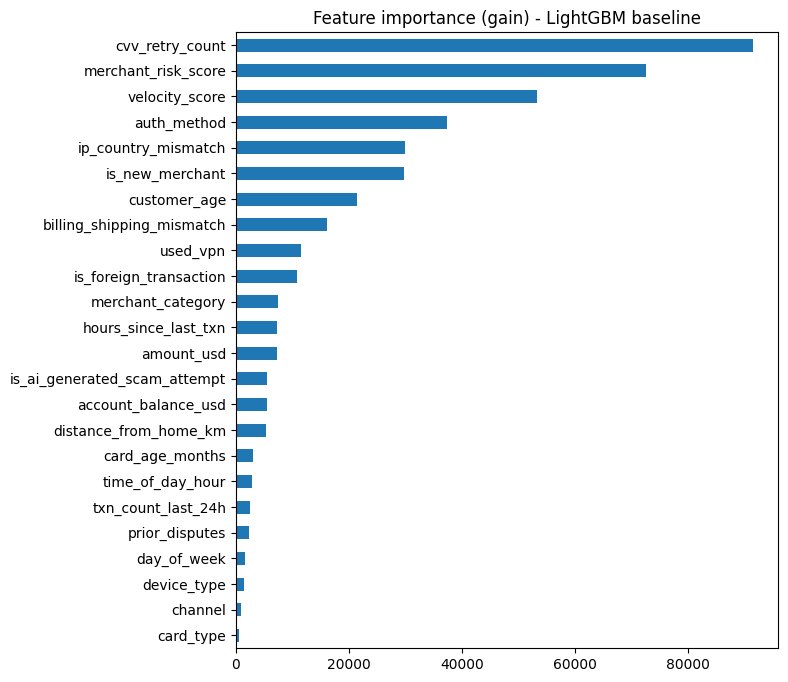

In [70]:
imp = pd.concat(importances, axis=1).mean(axis=1).sort_values()
imp.plot.barh(figsize=(7, 8), title='Feature importance (gain) - LightGBM baseline');

In [71]:
import shutil
shutil.copy(SUB_DIR / 'lgb_baseline.csv', SUB_DIR / 'baseline_submission.csv')
pd.read_csv(SUB_DIR / 'baseline_submission.csv').head()

,id,is_fraud
0,699960,0.000327
1,699961,0.000195
2,699962,0.081684
3,699963,0.001619
4,699964,0.001313


In [72]:
FILE_SUBMIT = SUB_DIR / 'baseline_submission.csv'
PESAN = f'lgb_baseline | CV {cv_lgb:.5f}'

SUBMIT_SEKARANG = False
if SUBMIT_SEKARANG:
    setup_kaggle()
    !kaggle competitions submit -c {COMP} -f "{FILE_SUBMIT}" -m "{PESAN}"
    !kaggle competitions submissions -c {COMP} | head -n 5
else:
    print('Belum submit. File:', FILE_SUBMIT)

Belum submit. File: ps-s6e11\submissions\baseline_submission.csv


In [73]:
def rank01(x):
    return (rankdata(x) - 1) / (len(x) - 1)


def load_models(names=None):
    if names is None:
        names = sorted(p.name[:-len('_oof.csv')] for p in OOF_DIR.glob('*_oof.csv'))
    O, T = {}, {}
    for n in names:
        o = train[[ID]].merge(pd.read_csv(OOF_DIR / f'{n}_oof.csv'), on=ID, how='left')
        t = sample[[ID]].merge(pd.read_csv(OOF_DIR / f'{n}_test.csv'), on=ID, how='left')
        assert o[TARGET].notna().all() and t[TARGET].notna().all(), f'{n}: id tidak lengkap'
        O[n], T[n] = rank01(o[TARGET].values), rank01(t[TARGET].values)
    return pd.DataFrame(O), pd.DataFrame(T)


def hill_climb(y, O, n_iter=50, tol=1e-6):
    names = list(O.columns)
    scores = {n: roc_auc_score(y, O[n]) for n in names}
    best = max(scores, key=scores.get)
    counts = dict.fromkeys(names, 0); counts[best] = 1
    blend, cur = O[best].values.copy(), scores[best]
    for i in range(1, n_iter):
        cand = {n: roc_auc_score(y, (blend * i + O[n].values) / (i + 1)) for n in names}
        nb = max(cand, key=cand.get)
        if cand[nb] - cur < tol:
            break
        blend = (blend * i + O[nb].values) / (i + 1)
        cur = cand[nb]; counts[nb] += 1
    total = sum(counts.values())
    return {n: c / total for n, c in counts.items() if c}, cur


def ensemble(names=None, out='ensemble'):
    y = train[TARGET].values
    O, T = load_models(names)
    print(f'{O.shape[1]} model:')
    for n in O.columns:
        print(f'  {n:<28} CV AUC {roc_auc_score(y, O[n]):.5f}')
    if O.shape[1] > 1:
        display(O.corr().round(3))

    eq_auc = roc_auc_score(y, O.mean(axis=1))
    w, hc_auc = hill_climb(y, O)
    hc_oof = sum(O[n] * v for n, v in w.items())
    fold_auc = [roc_auc_score(y[train.fold == k], hc_oof[train.fold == k]) for k in range(N_FOLDS)]
    print(f'\nRank-average CV AUC : {eq_auc:.5f}')
    print(f'Hill-climbing CV AUC: {hc_auc:.5f}  bobot={ {k: round(v, 3) for k, v in w.items()} }')
    print(f'Per-fold hill-climb : {np.round(fold_auc, 5)} (std {np.std(fold_auc):.5f})')

    for tag, p in [('rankavg', T.mean(axis=1)), ('hillclimb', sum(T[n] * v for n, v in w.items()))]:
        sub = sample[[ID]].copy(); sub[TARGET] = np.asarray(p)
        check_submission(sub)
        sub.to_csv(SUB_DIR / f'{out}_{tag}.csv', index=False)
        print('Tersimpan:', SUB_DIR / f'{out}_{tag}.csv')

ensemble()

1 model:
  lgb_baseline                 CV AUC 0.94632

Rank-average CV AUC : 0.94632
Hill-climbing CV AUC: 0.94632  bobot={'lgb_baseline': 1.0}
Per-fold hill-climb : [0.94459 0.94796 0.95091 0.94669 0.94174] (std 0.00309)
[OK] Format submission valid (299984 baris)
Tersimpan: ps-s6e11\submissions\ensemble_rankavg.csv
[OK] Format submission valid (299984 baris)
Tersimpan: ps-s6e11\submissions\ensemble_hillclimb.csv


In [74]:
pd.read_csv(ROOT / 'experiments.csv')

,waktu,nama,cv_auc,std_fold,public_lb
0,2026-11-03 21:35,lgb_baseline,0.946318,0.003092,NaN
1,2026-11-03 22:47,lgb_baseline,0.946318,0.003092,NaN
2,2026-11-03 23:11,lgb_baseline,0.946318,0.003092,NaN


# EDA, Data Hygiene & Preprocessing

## 1. Load, optimize memory, and audit

The loader downcasts numeric columns and converts low-cardinality text columns to `category`.



In [75]:
train, test, memory_report = eda.load_data(
    DATA_DIR / 'train.csv',
    DATA_DIR / 'test.csv',
)
print('train:', train.shape, 'test:', test.shape)
print(memory_report['train']['before_mb'], 'MB ->', memory_report['train']['after_mb'], 'MB')

audit = eda.basic_audit(train, test, target_col=TARGET, id_col=ID)
pd.Series(audit).to_frame('value')

NameError: name 'eda' is not defined

## 2. Target, outliers, and univariate signal

In [ ]:
features = [c for c in train.columns if c not in {TARGET, ID}]
numeric_features = [
    c for c in features
    if pd.api.types.is_numeric_dtype(train[c])
    and not pd.api.types.is_bool_dtype(train[c])
]
cat_features = [
    c for c in features
    if isinstance(train[c].dtype, pd.CategoricalDtype)
    or pd.api.types.is_object_dtype(train[c])
    or pd.api.types.is_string_dtype(train[c])
]
bool_features = [c for c in features if pd.api.types.is_bool_dtype(train[c])]

target_info = eda.target_summary(train, TARGET, ARTIFACT_DIR, show=True)
outliers = eda.outlier_report(train, numeric_features, ARTIFACT_DIR, show=True)
outliers.head(10)

In [ ]:
correlations = eda.correlation_report(
    train, TARGET, numeric_features, ARTIFACT_DIR, show=True
)
correlations.head(12)

In [ ]:
categorical = eda.categorical_report(
    train, cat_features, TARGET, ARTIFACT_DIR, show=True
)
booleans, risk_flags = eda.boolean_report(
    train, bool_features, TARGET, ARTIFACT_DIR, show=True
)
print('categorical rows:', len(categorical))
print('boolean rows:', len(booleans), 'risk rows:', len(risk_flags))
risk_flags

In [ ]:
eda.plot_feature_distributions(
    train,
    test,
    TARGET,
    correlations.head(6)['feature'].tolist(),
    ARTIFACT_DIR,
    show=True,
)

## 3. Adversarial validation

A small LightGBM model tries to distinguish train from test. AUC near 0.5 means the random split is safe.

In [ ]:
RUN_ADVERSARIAL = True

if RUN_ADVERSARIAL:
    adversarial = eda.adversarial_validation(
        train,
        test,
        target_col=TARGET,
        id_col=ID,
        outdir=ARTIFACT_DIR,
        max_per_side=150_000,
        n_splits=5,
        random_state=42,
        show=True,
    )
else:
    adversarial = {'status': 'skipped', 'reason': 'RUN_ADVERSARIAL=False'}

adversarial

## 4. Leakage-safe preprocessing

For LightGBM/CatBoost, use `categorical_mode='ordinal'` and pass the exposed categorical indices or names.

In [ ]:
y = train[TARGET].astype(np.int8)

prep = DataPreprocessor(
    target_col=TARGET,
    id_col=ID,
    categorical_mode='ordinal',
    scale_numeric=False,
    random_state=42,
)
X_train = prep.fit_transform(train, y)
X_test = prep.transform(test)

print('X_train:', X_train.shape, 'X_test:', X_test.shape)
print('columns match:', list(X_train.columns) == list(X_test.columns))
print('NaNs:', int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))
print('categorical names:', prep.get_cat_feature_names())
print('categorical indices:', prep.get_cat_feature_indices())
X_train.head()

In [ ]:
prep.summary()

## 5. Key findings

This is the same `KEY_FINDINGS.md` produced by `run_stage1.py`.

In [ ]:
markdown = eda.build_key_findings(
    audit=audit,
    target=target_info,
    outliers=outliers,
    correlations=correlations,
    categorical=categorical,
    booleans=booleans,
    risk_flags=risk_flags,
    adversarial=adversarial,
    preprocessor_summaries={'ordinal': prep.summary()},
    outdir=ARTIFACT_DIR,
)
path = eda.save_key_findings(markdown, ARTIFACT_DIR)
print('saved:', path)
display(Markdown(markdown))

# ORANG KEDUA

**Notebook sumber:** `01_eda_preprocessing.ipynb`

Seluruh cell asli di bagian ini dipertahankan tanpa perubahan. Output dan error tersimpan berasal dari notebook sumber; penggabungan ini tidak menjalankan ulang kode.


# Stage 1 - EDA, Data Hygiene & Leakage-Safe Preprocessing

Competition: **Predicting Credit Card Fraud (Playground S6E11)**  
Target: `is_fraud`; metric: **ROC-AUC**.

This notebook is a thin wrapper around `src.eda` and `src.preprocessing`. Upload the repository (or the `src` folder as a Kaggle dataset) and adjust `ROOT` if needed.

In [ ]:
from pathlib import Path
import sys

CANDIDATES = [
    Path.cwd(),
    Path.cwd().parent,
    Path('/kaggle/working'),
    Path('/kaggle/input/credit-card-fraud-stage1'),
]
for candidate in CANDIDATES:
    if (candidate / 'src').exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Upload the src/ folder or set ROOT manually')

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print('ROOT:', ROOT)

ROOT: f:\import doc\COLLAGE SEMESTER 7 TEL U\Visdat\tubes lomba UAS & UTS\tubesLomba_visdat


In [2]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import eda
from src.preprocessing import DataPreprocessor

DATA_DIR = ROOT / 'playground-series-s6e11'
if not DATA_DIR.exists():
    DATA_DIR = Path('/kaggle/input/playground-series-s6e11')

ARTIFACT_DIR = ROOT / 'artifacts'
TARGET = 'is_fraud'
ID = 'id'
print('DATA_DIR:', DATA_DIR)

ImportError: cannot import name 'eda' from 'src' (unknown location)

## 1. Load, optimize memory, and audit

The loader downcasts numeric columns and converts low-cardinality text columns to `category`.

In [3]:
train, test, memory_report = eda.load_data(
    DATA_DIR / 'train.csv',
    DATA_DIR / 'test.csv',
)
print('train:', train.shape, 'test:', test.shape)
print(memory_report['train']['before_mb'], 'MB ->', memory_report['train']['after_mb'], 'MB')

audit = eda.basic_audit(train, test, target_col=TARGET, id_col=ID)
pd.Series(audit).to_frame('value')

train: (699960, 26) test: (299984, 25)
136.68 MB -> 33.38 MB


,value
train_shape,"[699960, 26]"
test_shape,"[299984, 25]"
n_features,24
features,"[amount_usd, hours_since_last_txn, txn_count_l..."
train_columns,"[id, amount_usd, hours_since_last_txn, txn_cou..."
test_columns,"[id, amount_usd, hours_since_last_txn, txn_cou..."
test_missing_features,[]
target_col,is_fraud
target_dtype,float32
target_counts,"{'0': 688271, '1': 11689}"


## 2. Target, outliers, and univariate signal

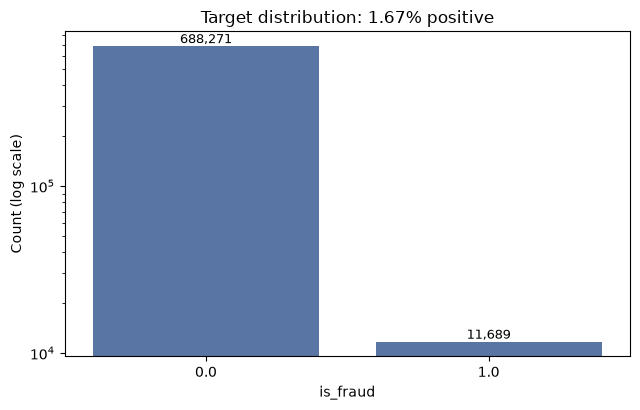

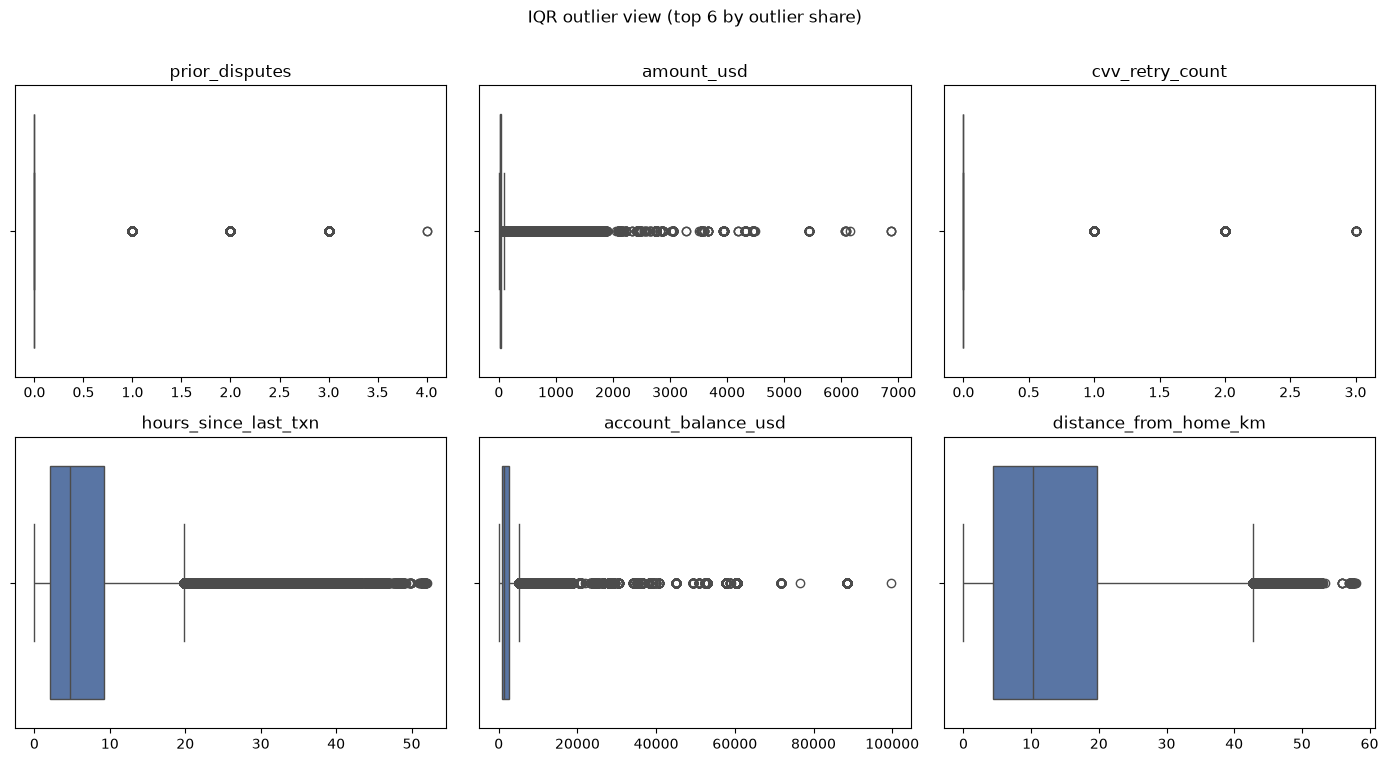

,feature,count,mean,std,min,q1,median,q3,max,skew,iqr_lower,iqr_upper,iqr_outliers,iqr_outlier_pct,zscore_outliers,zscore_outlier_pct
12,prior_disputes,699960,0.152769,0.381126,0.00,0.000000,0.000000,0.000000,4.000000,2.377010,0.000000,0.000000,101564,14.509972,5199,0.742757
0,amount_usd,699960,79.893066,205.173386,1.00,15.810000,27.250000,43.110001,6872.689941,7.002189,-25.140000,84.060001,70741,10.106435,18262,2.609006
7,cvv_retry_count,699960,0.085472,0.289524,0.00,0.000000,0.000000,0.000000,3.000000,3.318657,0.000000,0.000000,57872,8.267901,57872,8.267901
1,hours_since_last_txn,699960,6.633734,6.290128,0.01,2.110000,4.730000,9.190000,51.980000,1.823175,-8.510000,19.809999,32816,4.688268,12848,1.835533
6,account_balance_usd,699960,2064.998047,3400.130371,58.25,834.119995,1382.739990,2517.020020,99701.390625,14.436199,-1690.230042,5041.370056,29068,4.152809,3697,0.528173
3,distance_from_home_km,699960,13.587575,11.617317,0.00,4.430000,10.220000,19.750000,57.930000,1.059740,-18.550000,42.730000,16770,2.395851,5337,0.762472
11,merchant_risk_score,699960,35.217648,12.628351,0.00,26.400000,34.200001,42.700001,100.000000,0.619609,1.949998,67.150002,13028,1.861249,6294,0.899194
8,velocity_score,699960,18.929445,10.864377,0.00,11.400000,18.600000,26.000000,72.900002,0.259673,-10.500001,47.900001,4276,0.610892,1928,0.275444
2,txn_count_last_24h,699960,2.984092,1.498997,0.00,2.000000,3.000000,4.000000,11.000000,0.436433,-1.000000,7.000000,2704,0.386308,2704,0.386308
4,card_age_months,699960,46.862982,5.579186,25.00,43.000000,47.000000,51.000000,73.000000,0.132970,31.000000,63.000000,2253,0.321876,2253,0.321876


In [4]:
features = [c for c in train.columns if c not in {TARGET, ID}]
numeric_features = [
    c for c in features
    if pd.api.types.is_numeric_dtype(train[c])
    and not pd.api.types.is_bool_dtype(train[c])
]
cat_features = [
    c for c in features
    if isinstance(train[c].dtype, pd.CategoricalDtype)
    or pd.api.types.is_object_dtype(train[c])
    or pd.api.types.is_string_dtype(train[c])
]
bool_features = [c for c in features if pd.api.types.is_bool_dtype(train[c])]

target_info = eda.target_summary(train, TARGET, ARTIFACT_DIR, show=True)
outliers = eda.outlier_report(train, numeric_features, ARTIFACT_DIR, show=True)
outliers.head(10)

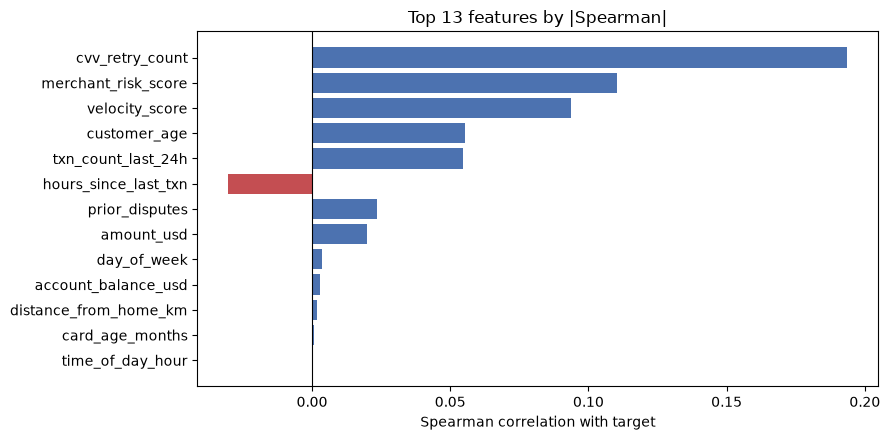

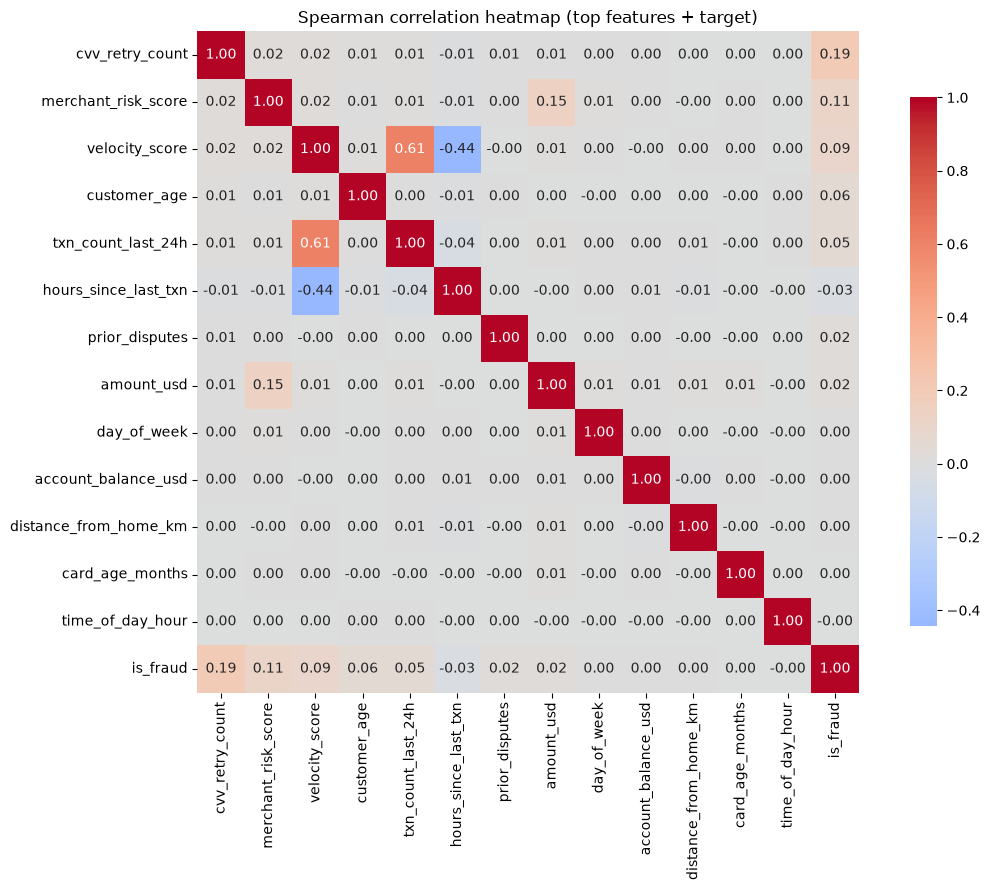

,feature,pearson,spearman,abs_pearson,abs_spearman
0,cvv_retry_count,0.212290,0.193620,0.212290,0.193620
1,merchant_risk_score,0.125391,0.110503,0.125391,0.110503
2,velocity_score,0.101650,0.093587,0.101650,0.093587
3,customer_age,0.056051,0.055374,0.056051,0.055374
4,txn_count_last_24h,0.058035,0.054539,0.058035,0.054539
5,hours_since_last_txn,-0.020490,-0.030284,0.020490,0.030284
6,prior_disputes,0.023644,0.023400,0.023644,0.023400
7,amount_usd,0.019443,0.019909,0.019443,0.019909
8,day_of_week,0.003651,0.003647,0.003651,0.003647
9,account_balance_usd,0.001077,0.002776,0.001077,0.002776


In [5]:
correlations = eda.correlation_report(
    train, TARGET, numeric_features, ARTIFACT_DIR, show=True
)
correlations.head(12)

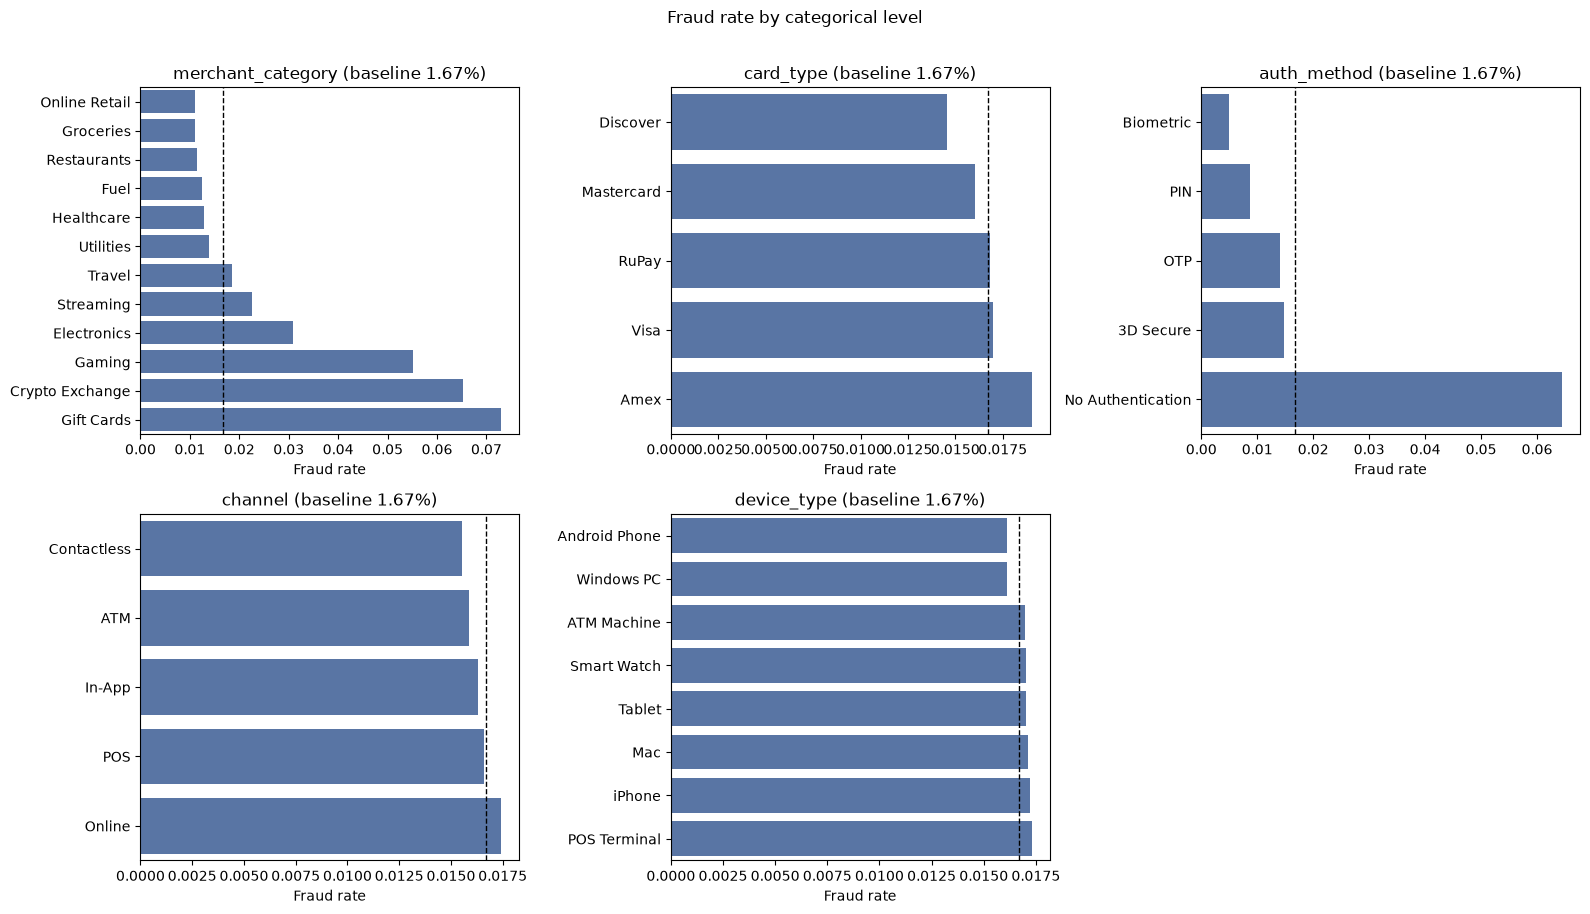

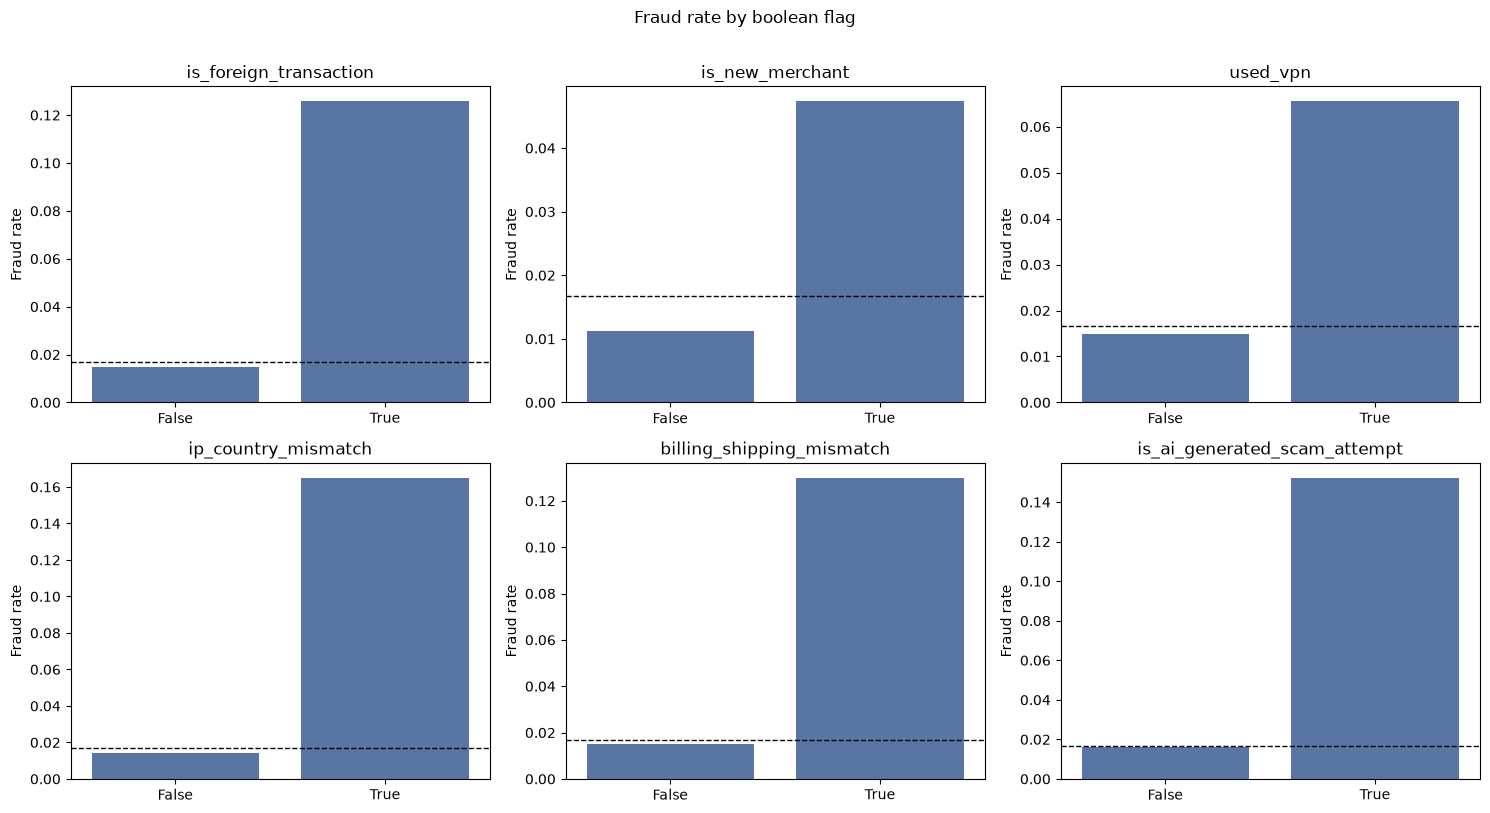

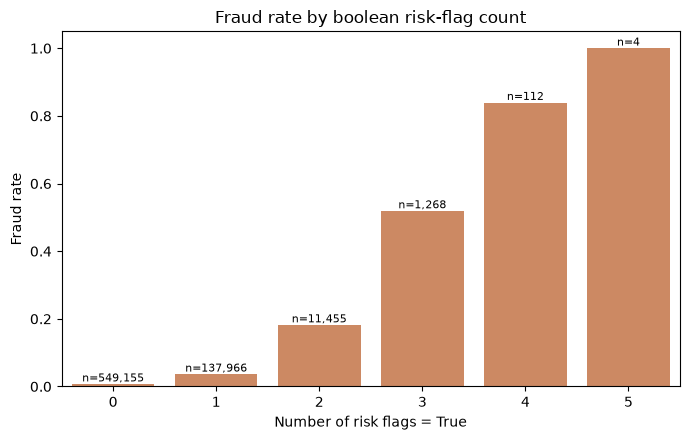

categorical rows: 35
boolean rows: 12 risk rows: 6


,risk_flags_sum,count,mean
0,0,549155,0.007047
1,1,137966,0.036103
2,2,11455,0.181755
3,3,1268,0.518927
4,4,112,0.839286
5,5,4,1.000000


In [6]:
categorical = eda.categorical_report(
    train, cat_features, TARGET, ARTIFACT_DIR, show=True
)
booleans, risk_flags = eda.boolean_report(
    train, bool_features, TARGET, ARTIFACT_DIR, show=True
)
print('categorical rows:', len(categorical))
print('boolean rows:', len(booleans), 'risk rows:', len(risk_flags))
risk_flags

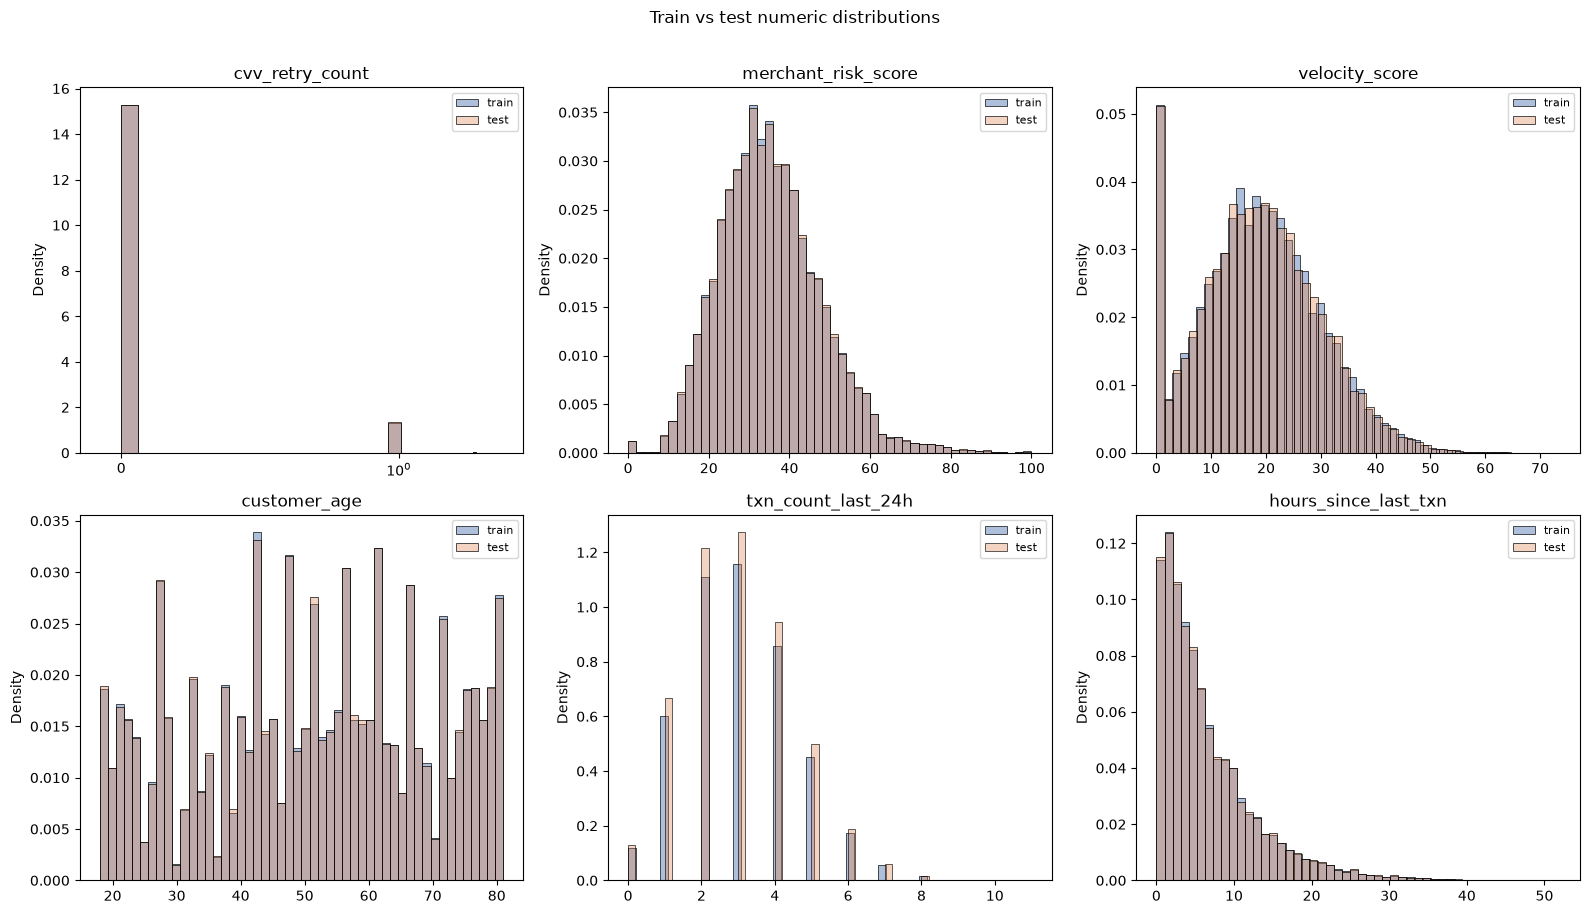

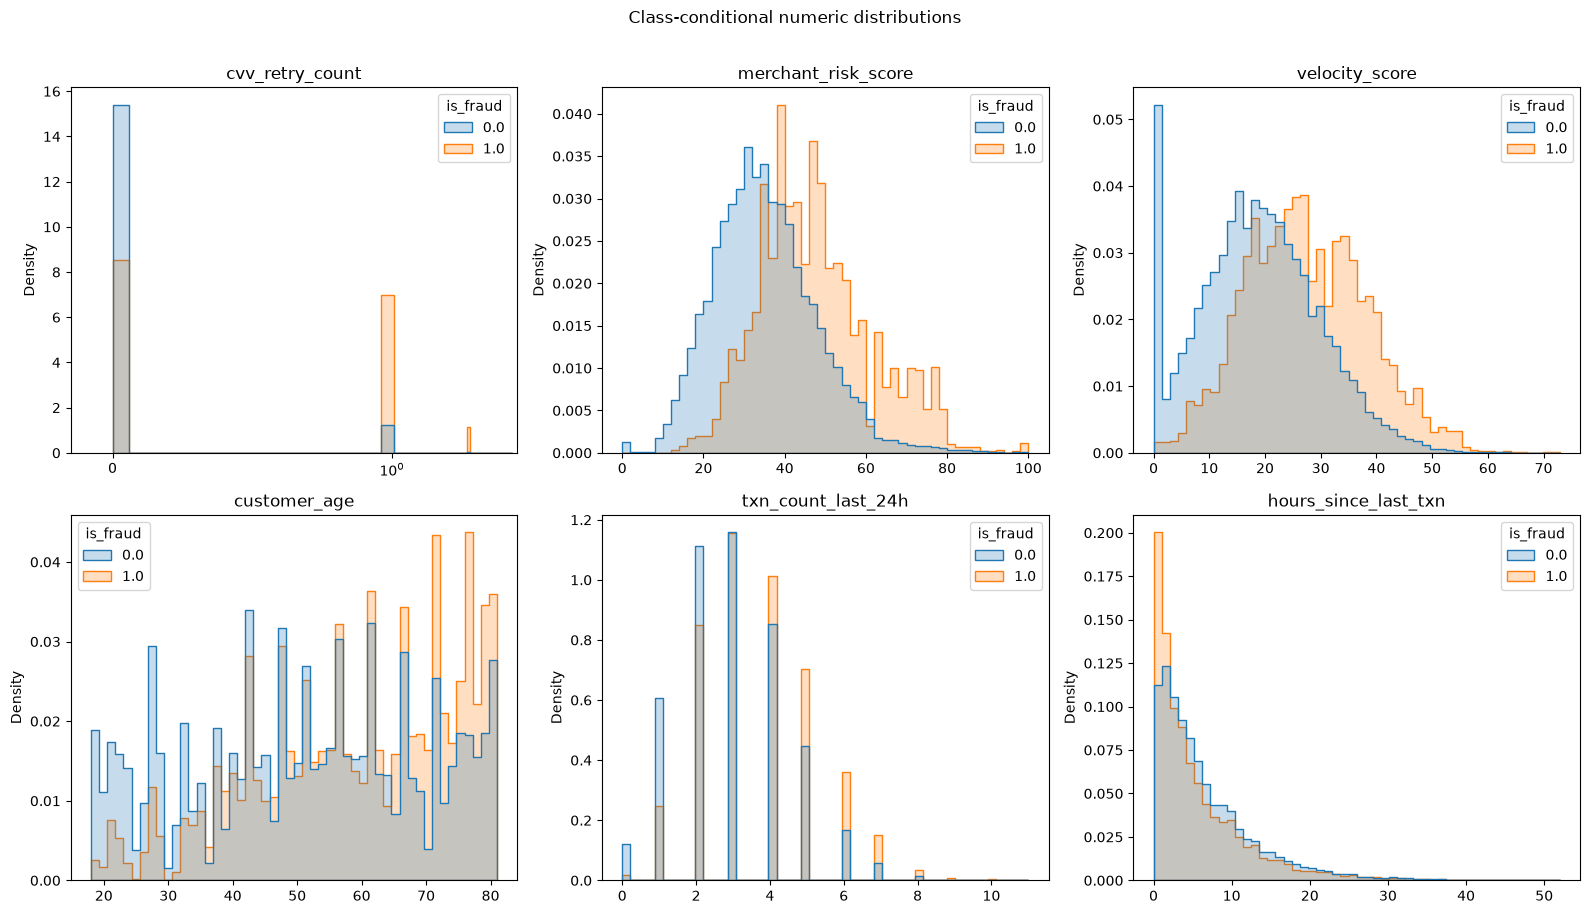

{'train_test': 'C:\\Users\\LENOVO\\Documents\\TUGAS\\VISDAT\\KOMPETISI\\artifacts\\eda\\numeric_distributions.png',
 'class': 'C:\\Users\\LENOVO\\Documents\\TUGAS\\VISDAT\\KOMPETISI\\artifacts\\eda\\class_distributions.png'}

In [7]:
eda.plot_feature_distributions(
    train,
    test,
    TARGET,
    correlations.head(6)['feature'].tolist(),
    ARTIFACT_DIR,
    show=True,
)

## 3. Adversarial validation

A small LightGBM model tries to distinguish train from test. AUC near 0.5 means the random split is safe.

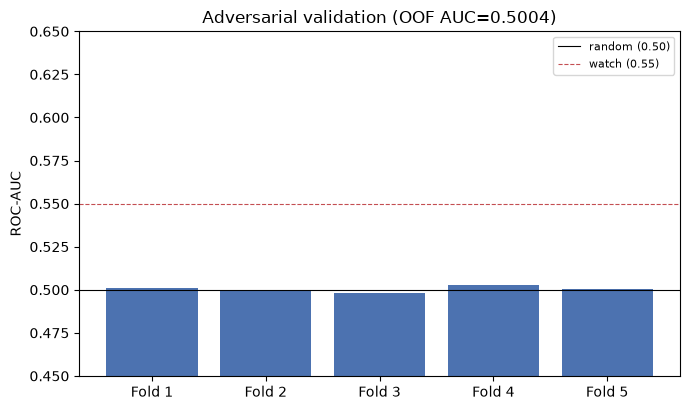

{'status': 'ok',
 'train_rows_used': 150000,
 'test_rows_used': 150000,
 'n_splits': 5,
 'oof_auc': 0.5003991174222222,
 'fold_aucs': [0.5010192888888889,
  0.4996861211111111,
  0.4981580211111111,
  0.5026935911111111,
  0.5006005288888888],
 'mean_fold_auc': 0.5004315102222222,
 'std_fold_auc': 0.0014976928045397258,
 'interpretation': 'no meaningful distribution drift',
 'top_drift_features': [{'feature': 'merchant_risk_score',
   'gain': 4547.673268938064},
  {'feature': 'hours_since_last_txn', 'gain': 4421.202146267891},
  {'feature': 'distance_from_home_km', 'gain': 4383.306520080567},
  {'feature': 'amount_usd', 'gain': 4340.2593645811085},
  {'feature': 'account_balance_usd', 'gain': 4144.5094192504885},
  {'feature': 'velocity_score', 'gain': 3798.3010776519777},
  {'feature': 'customer_age', 'gain': 3236.392221212387},
  {'feature': 'time_of_day_hour', 'gain': 2689.005683851242},
  {'feature': 'card_age_months', 'gain': 2488.9735899448397},
  {'feature': 'merchant_category',

In [8]:
RUN_ADVERSARIAL = True

if RUN_ADVERSARIAL:
    adversarial = eda.adversarial_validation(
        train,
        test,
        target_col=TARGET,
        id_col=ID,
        outdir=ARTIFACT_DIR,
        max_per_side=150_000,
        n_splits=5,
        random_state=42,
        show=True,
    )
else:
    adversarial = {'status': 'skipped', 'reason': 'RUN_ADVERSARIAL=False'}

adversarial

## 4. Leakage-safe preprocessing

For LightGBM/CatBoost, use `categorical_mode='ordinal'` and pass the exposed categorical indices or names.

In [9]:
y = train[TARGET].astype(np.int8)

prep = DataPreprocessor(
    target_col=TARGET,
    id_col=ID,
    categorical_mode='ordinal',
    scale_numeric=False,
    random_state=42,
)
X_train = prep.fit_transform(train, y)
X_test = prep.transform(test)

print('X_train:', X_train.shape, 'X_test:', X_test.shape)
print('columns match:', list(X_train.columns) == list(X_test.columns))
print('NaNs:', int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))
print('categorical names:', prep.get_cat_feature_names())
print('categorical indices:', prep.get_cat_feature_indices())
X_train.head()

X_train: (699960, 24) X_test: (299984, 24)
columns match: True
NaNs: 0 0
categorical names: ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
categorical indices: [13, 14, 15, 16, 17]


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,...,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,61.160000,9.77,1.0,17.780001,48.0,56.0,1269.349976,0.0,5.500000,17.0,...,2,3,4,7,0,0,0,0,0,0
1,24.830000,1.54,3.0,13.060000,38.0,28.0,3233.000000,0.0,33.400002,23.0,...,4,4,2,1,0,0,0,0,0,0
2,6.360000,1.20,4.0,8.170000,50.0,55.0,1046.880005,0.0,35.799999,15.0,...,4,3,3,5,0,0,1,0,0,0
3,37.439999,5.13,4.0,8.670000,48.0,48.0,2217.669922,0.0,20.700001,7.0,...,2,0,4,1,0,0,0,0,0,0
4,653.849976,0.80,4.0,11.690000,37.0,52.0,3291.060059,0.0,34.799999,4.0,...,4,0,3,6,0,0,0,0,0,0


In [10]:
prep.summary()

{'params': {'bool_as_int': True,
  'categorical_features': None,
  'categorical_imputer': 'constant',
  'categorical_mode': 'ordinal',
  'drop_constant': True,
  'id_col': 'id',
  'numeric_imputer': 'median',
  'random_state': 42,
  'scale_numeric': False,
  'scaler': 'standard',
  'target_col': 'is_fraud',
  'target_encode_folds': 5,
  'target_encode_smoothing': 20.0,
  'unseen_strategy': 'new',
  'verbose': True},
 'n_features_in': 24,
 'n_features_out': 24,
 'feature_names_in': ['amount_usd',
  'hours_since_last_txn',
  'txn_count_last_24h',
  'distance_from_home_km',
  'card_age_months',
  'customer_age',
  'account_balance_usd',
  'cvv_retry_count',
  'velocity_score',
  'time_of_day_hour',
  'day_of_week',
  'merchant_risk_score',
  'prior_disputes',
  'merchant_category',
  'card_type',
  'auth_method',
  'channel',
  'device_type',
  'is_foreign_transaction',
  'is_new_merchant',
  'used_vpn',
  'ip_country_mismatch',
  'billing_shipping_mismatch',
  'is_ai_generated_scam_attem

## 5. Key findings

This is the same `KEY_FINDINGS.md` produced by `run_stage1.py`.

In [11]:
markdown = eda.build_key_findings(
    audit=audit,
    target=target_info,
    outliers=outliers,
    correlations=correlations,
    categorical=categorical,
    booleans=booleans,
    risk_flags=risk_flags,
    adversarial=adversarial,
    preprocessor_summaries={'ordinal': prep.summary()},
    outdir=ARTIFACT_DIR,
)
path = eda.save_key_findings(markdown, ARTIFACT_DIR)
print('saved:', path)
display(Markdown(markdown))

saved: C:\Users\LENOVO\Documents\TUGAS\VISDAT\KOMPETISI\artifacts\KEY_FINDINGS.md


# Key Findings - Stage 1 EDA & Preprocessing

Competition: **Predicting Credit Card Fraud (Playground S6E11)**  
Target: `is_fraud` (binary), metric: **ROC-AUC**.

## 1. Dataset sanity

- Train: **699,960 x 26**; test: **299,984 x 25**.
- Fitur yang dipakai: **24** (kolom `id` dan target tidak masuk model).
- Missing values: train **0**, test **0**.
- Duplikasi baris: train **0**, test **0**.
- Fitur konstan/zero-variance: **0**.
- Overlap baris train-test: **0**; overlap `id`: **0**.
- Unseen categorical levels di test: **tidak ada**.
- Catatan schema: file lokal berisi 24 fitur (bukan 53); pipeline dibuat schema-agnostic.

## 2. Target dan imbalance

- Positif: **11,689** / **699,960** = **1.6700%**.
- Rasio negatif:positif = **58.9:1**.
- Optimalkan ROC-AUC, bukan accuracy. Jangan resample validation/test; lakukan resampling hanya di dalam fold training bila diperlukan.

## 3. Sinyal prediktif terkuat

- **cvv_retry_count** - Pearson 0.212, Spearman 0.194.
- **merchant_risk_score** - Pearson 0.125, Spearman 0.111.
- **velocity_score** - Pearson 0.102, Spearman 0.094.
- **customer_age** - Pearson 0.056, Spearman 0.055.
- **txn_count_last_24h** - Pearson 0.058, Spearman 0.055.
- **hours_since_last_txn** - Pearson -0.020, Spearman -0.030.

## 4. Segmen berisiko tinggi

- `merchant_category` = **Gift Cards**: 7.30% fraud (n=9,456, lift 4.37x).
- `auth_method` = **No Authentication**: 6.44% fraud (n=67,060, lift 3.86x).
- `card_type` = **Amex**: 1.90% fraud (n=45,797, lift 1.14x).
- `channel` = **Online**: 1.74% fraud (n=273,939, lift 1.04x).
- `device_type` = **POS Terminal**: 1.73% fraud (n=113,237, lift 1.04x).
- `ip_country_mismatch` = **True**: 16.50% fraud (n=11,312, lift 9.88x).
- `is_ai_generated_scam_attempt` = **True**: 15.22% fraud (n=2,299, lift 9.12x).
- `billing_shipping_mismatch` = **True**: 12.99% fraud (n=9,054, lift 7.78x).
- `is_foreign_transaction` = **True**: 12.57% fraud (n=12,098, lift 7.53x).
- `used_vpn` = **True**: 6.55% fraud (n=23,665, lift 3.92x).

**Fraud rate berdasarkan jumlah flag risiko:**

- 0 flag: 0.70% (n=549,155).
- 1 flag: 3.61% (n=137,966).
- 2 flag: 18.18% (n=11,455).
- 3 flag: 51.89% (n=1,268).
- 4 flag: 83.93% (n=112).
- 5 flag: 100.00% (n=4).

## 5. Keanehan data dan catatan hygiene

- `prior_disputes`: 14.51% IQR outliers (skew 2.38). **Jangan drop otomatis**; ini tail yang mungkin informatif.
- `amount_usd`: 10.11% IQR outliers (skew 7.00). **Jangan drop otomatis**; ini tail yang mungkin informatif.
- `cvv_retry_count`: 8.27% IQR outliers (skew 3.32). **Jangan drop otomatis**; ini tail yang mungkin informatif.
- `cvv_retry_count` sangat zero-inflated; pertimbangkan count + binary flag (`cvv_retry_count > 0`).
- `amount_usd` dan `account_balance_usd` right-skewed; kandidat `log1p` untuk model linear/NN.
- Test memiliki beberapa nilai sedikit di luar rentang train (`distance_from_home_km`, `card_age_months`, `account_balance_usd`, `velocity_score`). **Jangan clip** ke min/max train.
- `id` hanya identifier; jangan dipakai sebagai fitur.

## 6. Adversarial validation

- OOF ROC-AUC: **0.5004** (mean fold 0.5004 +/- 0.0015).
- Interpretasi: **no meaningful distribution drift**.
- Fitur dengan gain tertinggi pada classifier adversarial: `merchant_risk_score`, `hours_since_last_txn`, `distance_from_home_km`. Gain ini **tidak menunjukkan drift nyata** karena AUC mendekati 0.5.
- CV acak aman dipakai; tidak perlu adversarial weighting kecuali skor berubah jauh di run lain.

## 7. Rekomendasi untuk Feature Engineering & Modeling

- Gunakan **StratifiedKFold**; jangan bocorkan target lewat agregasi atau target encoding.
- Kandidat fitur baru: `risk_flags_sum`, `cvv_retry_flag`, `log1p(amount_usd)`, `log1p(account_balance_usd)`, `amount_to_balance_ratio`, `txn_velocity = txn_count_last_24h / (hours_since_last_txn + 1)`.
- Interaksi prioritas: `merchant_category x auth_method`, `merchant_risk_score x risk_flags_sum`, `cvv_retry_count x auth_method`.
- `time_of_day_hour`, `day_of_week`, `distance_from_home_km`, `card_age_months`, dan `account_balance_usd` lemah secara univariat; jangan langsung drop, biarkan model mencari interaksi.
- Untuk LightGBM/CatBoost, pakai `categorical_mode='ordinal'` dan deklarasikan categorical feature. Untuk model linear/NN, gunakan `onehot` dan scaling.
- Prefer class weight / `scale_pos_weight` daripada SMOTE. ROC-AUC tidak membutuhkan kalibrasi probabilitas.

## 8. Handoff

Artefak utama:

- `C:\Users\LENOVO\Documents\TUGAS\VISDAT\KOMPETISI\artifacts\processed` - data siap model per encoding.
- `C:\Users\LENOVO\Documents\TUGAS\VISDAT\KOMPETISI\artifacts\eda` - plot, tabel korelasi, audit, adversarial.
- `C:\Users\LENOVO\Documents\TUGAS\VISDAT\KOMPETISI\artifacts\KEY_FINDINGS.md` - file ini.

Ringkasan preprocessor:

- **ordinal**: 24 -> 24 fitur; categorical indices: [13, 14, 15, 16, 17].

Pola aman untuk loop StratifiedKFold Orang 1:

```python
from src.preprocessing import DataPreprocessor

for fold, (tr_idx, va_idx) in enumerate(skf.split(train, y)):
    prep = DataPreprocessor(categorical_mode='ordinal')
    X_tr = prep.fit_transform(train.iloc[tr_idx], y.iloc[tr_idx])
    X_va = prep.transform(train.iloc[va_idx])
    X_te = prep.transform(test)
```

LightGBM native categorical:

```python
model.fit(
    X_tr,
    y_tr,
    categorical_feature=prep.get_cat_feature_indices(),
)
```

CatBoost native categorical:

```python
model.fit(
    X_tr,
    y_tr,
    cat_features=prep.get_cat_feature_names(),
)
```

Untuk target encoding, panggil `fit_transform` di fold training dan `transform` di validation; jangan fit sekali di full train untuk CV.

---
Dibuat otomatis oleh `run_stage1.py`. Angka di atas dihitung dari dataset yang sedang dijalankan.

# ORANG KETIGA

**Notebook sumber:** `03_feature_engineering.ipynb`

Seluruh cell asli di bagian ini dipertahankan tanpa perubahan. Output dan error tersimpan berasal dari notebook sumber; penggabungan ini tidak menjalankan ulang kode.


# Person 3 - Feature Engineering

A self-contained notebook for creating fraud-detection features, comparing
five-fold ROC-AUC, and exporting datasets. No local Python modules are required.

## Reading guide

| Sections | Purpose |
|---|---|
| 1-2 | Configure execution and load data with the team's folds |
| 3-4 | Define row-level features, fold-level aggregates, and encoding |
| 5-6 | Run optional feature checks and inspect a small preview |
| 7-8 | Configure LightGBM and run CV or load saved experiments |
| 9-10 | Compare scores and inspect saved predictions |
| 11-13 | Export features, integrate with the team, and read the report |

Start with sections **3 and 4** to understand the feature formulas.
Run cells from top to bottom when executing the notebook.

## 1. Execution settings

Select a Python 3.12 kernel, then use **Restart Kernel & Run All**.
The original CSV files are in `ps-s6e11/data/`.

- `USE_PREPROCESSED_DATA=True` requires the Parquet exports and manifest in
  `ps-s6e11/preprocessed/`. Use `False` when working directly with the raw CSVs.
- `RUN_CV=False` reads compatible saved results; `True` trains the CV models.
- `EXPORT_DATASETS=True` rebuilds the engineered Parquet files.
- `RUN_CHECKS=True` runs the existing feature checks.

In [28]:
# Environment setup: enable installation only when packages are missing.
INSTALL_DEPENDENCIES = False

# Execution: checks, model evaluation, and dataset export are independent.
RUN_CHECKS = True
RUN_CV = False
EXPORT_DATASETS = True

# True: read the preprocessing exports. False: read the original CSV files.
USE_PREPROCESSED_DATA = False

# Optional repository path when launching from another working directory.
PROJECT_ROOT = None

### Optional dependency installation

In [29]:
if INSTALL_DEPENDENCIES:
    get_ipython().run_line_magic(
        'pip',
        'install --use-feature=truststore '
        'numpy==2.2.3 pandas==2.2.3 scikit-learn==1.6.1 '
        'lightgbm==4.7.0 pyarrow==25.0.1 matplotlib==3.10.1',
    )
else:
    print('Using the active kernel environment.')

Using the active kernel environment.


### Imports

In [30]:
import ast
import hashlib
import inspect
import json
import platform
import textwrap
import time
import unittest
from importlib.metadata import version
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import Markdown, display
from sklearn.metrics import roc_auc_score

### 1.1. Project paths

In [31]:
# Locate the repository from an explicit path or the current directory.
if PROJECT_ROOT is not None:
    ROOT = Path(PROJECT_ROOT).expanduser().resolve()
else:
    ROOT = next(
        (
            directory
            for directory in [Path.cwd(), *Path.cwd().parents]
            if (directory / 'ps-s6e11' / 'data' / 'train.csv').is_file()
        ),
        None,
    )
    if ROOT is None:
        raise FileNotFoundError(
            'Set PROJECT_ROOT to the repository folder containing ps-s6e11/data.'
        )

# Raw inputs, feature exports, and experiment results.
DATA_DIR = ROOT / 'ps-s6e11' / 'data'
FEATURE_DIR = ROOT / 'ps-s6e11' / 'features'
HISTORICAL_OUTPUT_DIR = FEATURE_DIR / 'experiments'
CV_OUTPUT_DIR = FEATURE_DIR / 'notebook_experiments'
CV_REPORT_DIR = ROOT / 'reports' / 'notebook'
print('ROOT:', ROOT)
print('Python:', platform.python_version(), '| LightGBM:', lgb.__version__)
PREPROCESSED_DIR = ROOT / 'ps-s6e11' / 'preprocessed'
if USE_PREPROCESSED_DATA:
    CV_OUTPUT_DIR = FEATURE_DIR / 'notebook_experiments_preprocessed'
    CV_REPORT_DIR = ROOT / 'reports' / 'notebook_preprocessed'

ROOT: f:\import doc\COLLAGE SEMESTER 7 TEL U\Visdat\tubes lomba UAS & UTS\tubesLomba_visdat
Python: 3.12.3 | LightGBM: 4.7.0


## 2. Dataset and team folds

The dataset has 24 original features: 13 numeric, 5 categorical, and 6 boolean. `id` and `is_fraud` are excluded from model features.
Use Person 1's five folds from `folds.csv`. There is no customer ID or full timestamp,
so merchant/channel aggregates do not represent customer history.

In [32]:
def digest(path):
    """Compute a file hash without loading the entire file into memory."""
    hasher = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            hasher.update(block)
    return hasher.hexdigest()


def read_input_frame(data_dir, name):
    """Read raw CSV data or preprocessing exports with matching provenance."""
    if not USE_PREPROCESSED_DATA:
        return pd.read_csv(data_dir / f'{name}.csv')

    manifest_path = PREPROCESSED_DIR / 'manifest.json'
    if not manifest_path.exists():
        raise FileNotFoundError(
            'Run 01_eda_preprocessing.ipynb first, '
            'or set USE_PREPROCESSED_DATA=False.'
        )
    metadata = json.loads(manifest_path.read_text(encoding='utf-8'))
    for filename, expected in metadata['raw_sha256'].items():
        if digest(data_dir / filename) != expected:
            raise ValueError('Raw data changed. Rerun 01_eda_preprocessing.ipynb.')

    path = PREPROCESSED_DIR / f'{name}_preprocessed.parquet'
    if digest(path) != metadata['parquet_sha256'][name]:
        raise ValueError(
            'Preprocessed data changed. Rerun 01_eda_preprocessing.ipynb.'
        )
    return pd.read_parquet(path)

### 2.1. Dataset loading and fold validation

In [33]:
def load_data(data_dir):
    """Load datasets and align the team's five folds to training IDs."""
    train = read_input_frame(data_dir, 'train')
    test = read_input_frame(data_dir, 'test')
    folds = pd.read_csv(data_dir / 'folds.csv')
    sample = pd.read_csv(data_dir / 'sample_submission.csv')

    # Check identities before aligning fold assignments.
    for name, frame in [
        ('train', train),
        ('test', test),
        ('folds', folds),
        ('sample', sample),
    ]:
        if frame.id.isna().any() or frame.id.duplicated().any():
            raise ValueError(f'{name}: IDs must be unique and non-null')
    if set(train.id) != set(folds.id) or set(test.id) != set(sample.id):
        raise ValueError('IDs do not match folds/sample submission')
    if set(train.id) & set(test.id):
        raise ValueError('Train and test IDs overlap')
    if not train.is_fraud.isin([0, 1]).all():
        raise ValueError('Target must be non-missing binary labels')

    fold = folds.set_index('id').loc[train.id, 'fold'].to_numpy()
    if set(fold) != set(range(5)):
        raise ValueError('Expected exactly folds 0..4 from the team')
    for fold_index in range(5):
        if train.loc[fold == fold_index, 'is_fraud'].nunique() != 2:
            raise ValueError(f'Fold {fold_index} must contain both classes')

    return train, test, sample, fold

In [34]:
train, test, sample, fold = load_data(DATA_DIR)
print('train:', train.shape, '| test:', test.shape)
print(f'Fraud rate: {train.is_fraud.mean():.4%}')

display(
    pd.DataFrame({'fold': fold, 'is_fraud': train.is_fraud})
    .groupby('fold')
    .is_fraud.agg(['size', 'mean'])
)

train: (699960, 26) | test: (299984, 25)
Fraud rate: 1.6700%


,size,mean
fold,,
0,139992,0.016694
1,139992,0.016701
2,139992,0.016701
3,139992,0.016701
4,139992,0.016701


## 3. Row-level features

| Group | Added | Description |
|---|---:|---|
| monetary | 4 | Log amount/balance, amount-to-balance ratio, balance minus amount |
| activity | 6 | Log transaction gap, count/(gap+1), velocity * count, amount * count, retries+disputes, card age relative to customer age |
| temporal | 5 | Sine/cosine encodings of hour and day, hour-of-week index |
| risk | 5 | Risk-flag count, VPN/IP and foreign/IP interactions, merchant risk * amount, new merchant * amount |

Amount * transaction count is a numeric interaction, not actual 24-hour spending.
Zero denominators produce missing values, which LightGBM handles.
Row-level features can be created before CV because they do not learn statistics from other rows.

In [35]:
# Original input schema. Keep this order to preserve baseline colsample behavior.
CAT_COLS = (
    'merchant_category',
    'card_type',
    'auth_method',
    'channel',
    'device_type',
)
BOOL_COLS = (
    'is_foreign_transaction',
    'is_new_merchant',
    'used_vpn',
    'ip_country_mismatch',
    'billing_shipping_mismatch',
    'is_ai_generated_scam_attempt',
)
NUM_COLS = (
    'amount_usd',
    'hours_since_last_txn',
    'txn_count_last_24h',
    'distance_from_home_km',
    'card_age_months',
    'customer_age',
    'account_balance_usd',
    'cvv_retry_count',
    'velocity_score',
    'time_of_day_hour',
    'day_of_week',
    'merchant_risk_score',
    'prior_disputes',
)
BASE_COLS = NUM_COLS + CAT_COLS + BOOL_COLS

# Experiment groups and their aggregation keys.
ROW_GROUPS = ('monetary', 'activity', 'temporal', 'risk')
ALL_GROUPS = ROW_GROUPS + ('aggregate',)
GROUP_SPECS = (
    ('merchant_category', 'amount_usd'),
    ('merchant_category', 'velocity_score'),
    ('channel', 'txn_count_last_24h'),
)

### 3.1. Shared feature helpers

In [36]:
def validate_groups(groups):
    """Return an ordered tuple of unique, supported feature groups."""
    groups = tuple(groups)
    invalid = set(groups) - set(ALL_GROUPS)
    if invalid or len(groups) != len(set(groups)):
        raise ValueError(f'Invalid/duplicate feature groups: {groups}')
    return groups


def safe_ratio(numerator, denominator):
    """A zero denominator stays missing instead of producing infinity."""
    return numerator.astype(float).div(
        denominator.astype(float).replace(0, np.nan)
    )


def normalize_bool(series):
    """Normalize supported boolean representations; reject unknown values."""
    result = (
        series.astype('string')
        .str.strip()
        .str.lower()
        .map({'true': 1, 'false': 0, '1': 1, '0': 0, '1.0': 1, '0.0': 0})
    )
    if (series.notna() & result.isna()).any():
        raise ValueError(f'Unexpected boolean value in {series.name}')
    return result.astype(float)

### 3.2. Row-level feature formulas

In [37]:
def add_row_features(frame, groups=ROW_GROUPS):
    """Build model inputs using only values from each individual row.

    The input is copied. IDs, labels, and fold assignments are excluded.
    Column order follows the original schema, then the selected feature blocks.
    """
    groups = validate_groups(groups)
    missing = set(BASE_COLS) - set(frame.columns)
    if missing:
        raise ValueError(f'Missing raw features: {sorted(missing)}')

    # Normalize original numeric and boolean inputs.
    features = frame.loc[:, BASE_COLS].copy()
    for column in NUM_COLS:
        features[column] = pd.to_numeric(
            features[column], errors='raise'
        ).replace([np.inf, -np.inf], np.nan)
    for column in BOOL_COLS:
        features[column] = normalize_bool(features[column])

    # Monetary signals: transaction size and available balance.
    if 'monetary' in groups:
        for column in ('amount_usd', 'account_balance_usd'):
            features[f'fe_log1p_{column}'] = np.log1p(
                features[column].clip(lower=0)
            )
        features['fe_amount_balance_ratio'] = safe_ratio(
            features.amount_usd, features.account_balance_usd
        )
        features['fe_balance_minus_amount'] = (
            features.account_balance_usd - features.amount_usd
        )

    # Activity signals: frequency, velocity, and account/card context.
    if 'activity' in groups:
        features['fe_log1p_gap_hours'] = np.log1p(
            features.hours_since_last_txn.clip(lower=0)
        )
        features['fe_count_per_gap_plus_hour'] = safe_ratio(
            features.txn_count_last_24h, features.hours_since_last_txn + 1
        )
        features['fe_velocity_times_count'] = (
            features.velocity_score * features.txn_count_last_24h
        )
        features['fe_amount_times_count'] = (
            features.amount_usd * features.txn_count_last_24h
        )
        features['fe_cvv_plus_disputes'] = (
            features.cvv_retry_count + features.prior_disputes
        )
        features['fe_card_age_customer_age_ratio'] = safe_ratio(
            features.card_age_months, features.customer_age * 12
        )

    # Temporal signals: cyclic hour/day encodings and the hour of the week.
    if 'temporal' in groups:
        for column, period in [('time_of_day_hour', 24), ('day_of_week', 7)]:
            angle = 2 * np.pi * features[column] / period
            features[f'fe_{column}_sin'] = np.sin(angle)
            features[f'fe_{column}_cos'] = np.cos(angle)
        features['fe_hour_of_week'] = (
            24 * features.day_of_week + features.time_of_day_hour
        )

    # Risk signals: flag counts and interactions with transaction amount.
    if 'risk' in groups:
        features['fe_risk_flag_count'] = features[list(BOOL_COLS)].sum(
            axis=1, min_count=len(BOOL_COLS)
        )
        features['fe_vpn_ip_mismatch'] = (
            features.used_vpn * features.ip_country_mismatch
        )
        features['fe_foreign_ip_mismatch'] = (
            features.is_foreign_transaction * features.ip_country_mismatch
        )
        features['fe_merchant_risk_times_amount'] = (
            features.merchant_risk_score * features.amount_usd
        )
        features['fe_new_merchant_times_amount'] = (
            features.is_new_merchant * features.amount_usd
        )

    return features

## 4. Fold-level aggregation and encoding

**21 added features:** mean/std/min/max, difference from mean, ratio to mean, and z-score for:

- `amount_usd` by `merchant_category`;
- `velocity_score` by `merchant_category`;
- `txn_count_last_24h` by `channel`.

Create a new instance for each fold. `fit` sees only the training fold; validation/test use `transform`.
Unseen categories become missing. Unseen groups use global statistics learned from the training fold.
ID, target, and fold labels are excluded from model features.

In [38]:
class FraudFeatureEngineer:
    """Learn category vocabularies and group statistics on training rows only.

    Create one instance per CV fold. Use fit_transform on the training subset,
    then transform on validation and test data with the same instance.
    """

    def __init__(self, groups=ROW_GROUPS):
        self.groups = validate_groups(groups)

    def fit(self, frame, y=None):
        """Store training categories, aggregate tables, and output column names."""
        if frame.empty:
            raise ValueError('Cannot fit an empty training set')

        features = add_row_features(frame, self.groups)
        self.categories_ = {
            column: sorted(features[column].dropna().astype(str).unique())
            for column in CAT_COLS
        }
        self.stats_ = {}

        if 'aggregate' in self.groups:
            for group_column, value_column in GROUP_SPECS:
                values = pd.DataFrame({
                    'key': features[group_column].astype('string'),
                    'value': features[value_column],
                })
                table = values.groupby('key', observed=True)['value'].agg(
                    ['mean', 'std', 'min', 'max']
                )
                table['std'] = table['std'].fillna(0)
                fallback = values['value'].agg(
                    ['mean', 'std', 'min', 'max']
                ).fillna(0)
                self.stats_[group_column, value_column] = (table, fallback)

        self.feature_names_ = self.transform(frame.iloc[:1]).columns.tolist()
        return self

    def transform(self, frame):
        """Apply fitted statistics and categories without learning from frame."""
        if not hasattr(self, 'categories_'):
            raise ValueError('Call fit before transform')

        features = add_row_features(frame, self.groups)

        # Unknown groups fall back to statistics from the training fold.
        for (group_column, value_column), (table, fallback) in self.stats_.items():
            prefix = f'fe_{value_column}_by_{group_column}'
            group_keys = features[group_column].astype('string')
            for statistic in ('mean', 'std', 'min', 'max'):
                features[f'{prefix}_{statistic}'] = (
                    group_keys.map(table[statistic])
                    .fillna(fallback[statistic])
                    .astype(float)
                )
            features[f'{prefix}_diff'] = (
                features[value_column] - features[f'{prefix}_mean']
            )
            features[f'{prefix}_ratio'] = safe_ratio(
                features[value_column], features[f'{prefix}_mean']
            )
            features[f'{prefix}_zscore'] = safe_ratio(
                features[f'{prefix}_diff'], features[f'{prefix}_std']
            )

        # Unknown categories become missing, using training vocabulary only.
        for column in CAT_COLS:
            features[column] = features[column].astype('string').astype(
                pd.CategoricalDtype(self.categories_[column])
            )

        # Narrow only engineered columns to reduce memory usage.
        for column in features.columns:
            if column.startswith('fe_'):
                features[column] = features[column].replace(
                    [np.inf, -np.inf], np.nan
                ).astype('float32')

        return features

    def fit_transform(self, frame, y=None):
        """Fit on frame and return its model-ready features."""
        return self.fit(frame, y).transform(frame)

    def get_feature_names_out(self):
        """Return feature names in model input order."""
        return np.array(self.feature_names_, dtype=object)

## 5. Feature checks

Five checks verify that target/ID/fold never enter features, aggregates use training rows only,
unseen categories and zero denominators are handled, row features are independent, and schemas are validated.

In [39]:
def example():
    frame = pd.DataFrame({c: [1., 2., 3., 4.] for c in NUM_COLS})
    for c in CAT_COLS:
        frame[c] = ['a', 'a', 'b', 'b']
    for c in BOOL_COLS:
        frame[c] = [False, True, False, True]
    frame['id'] = [10, 20, 30, 40]
    frame['is_fraud'] = [0, 1, 0, 1]
    return frame


class FeatureChecks(unittest.TestCase):
    def test_target_id_fold_cannot_enter_features(self):
        raw = example()
        expected = FraudFeatureEngineer(ALL_GROUPS).fit_transform(raw)
        raw['is_fraud'] = 1 - raw.is_fraud
        raw['id'] += 1000
        raw['fold'] = [4, 3, 2, 1]
        actual = FraudFeatureEngineer(ALL_GROUPS).fit_transform(raw)
        pd.testing.assert_frame_equal(expected, actual)
        self.assertFalse({'id', 'is_fraud', 'fold'} & set(actual))

    def test_aggregate_uses_training_only(self):
        train = example()
        engineer = FraudFeatureEngineer(('aggregate',)).fit(train)
        valid = example().iloc[[0]].copy()
        valid['amount_usd'] = 1000000
        transformed = engineer.transform(valid)
        self.assertEqual(transformed['fe_amount_usd_by_merchant_category_mean'].iloc[0], 1.5)
        valid['merchant_category'] = 'unseen'
        transformed = engineer.transform(valid)
        self.assertEqual(transformed['fe_amount_usd_by_merchant_category_mean'].iloc[0], 2.5)
        self.assertTrue(transformed.merchant_category.isna().all())

    def test_zero_missing_and_constant_groups(self):
        raw = example()
        raw['amount_usd'] = 5.
        raw['account_balance_usd'] = 0.
        raw['customer_age'] = 0.
        raw.loc[1, 'merchant_category'] = None
        raw['used_vpn'] = raw['used_vpn'].astype('boolean')
        raw.loc[0, 'used_vpn'] = None
        result = FraudFeatureEngineer(ALL_GROUPS).fit_transform(raw)
        self.assertFalse(np.isinf(result.select_dtypes('number').to_numpy()).any())
        self.assertTrue(result.fe_amount_balance_ratio.isna().all())
        self.assertTrue(result.fe_amount_usd_by_merchant_category_zscore.isna().all())
        self.assertTrue(pd.isna(result.fe_risk_flag_count.iloc[0]))

    def test_stateless_row_features_and_index_order(self):
        raw = example()
        raw.index = [19, 3, 82, 0]
        all_rows = add_row_features(raw)
        one = add_row_features(raw.iloc[[2]])
        pd.testing.assert_frame_equal(all_rows.iloc[[2]], one)
        self.assertEqual(all_rows.index.tolist(), raw.index.tolist())

    def test_baseline_and_schema_validation(self):
        self.assertEqual(list(FraudFeatureEngineer(()).fit_transform(example())), list(BASE_COLS))
        with self.assertRaises(ValueError):
            FraudFeatureEngineer(('typo',))
        with self.assertRaises(ValueError):
            add_row_features(example().drop(columns='amount_usd'))
        raw = example()
        raw['used_vpn'] = 'not-a-boolean'
        with self.assertRaises(ValueError):
            add_row_features(raw)

In [40]:
if RUN_CHECKS:
    checks = unittest.TextTestRunner(verbosity=2).run(
        unittest.defaultTestLoader.loadTestsFromTestCase(FeatureChecks)
    )
    if not checks.wasSuccessful():
        raise AssertionError('Fix the feature checks before training.')

test_aggregate_uses_training_only (__main__.FeatureChecks.test_aggregate_uses_training_only) ... ok
test_baseline_and_schema_validation (__main__.FeatureChecks.test_baseline_and_schema_validation) ... ok
test_stateless_row_features_and_index_order (__main__.FeatureChecks.test_stateless_row_features_and_index_order) ... ok
test_target_id_fold_cannot_enter_features (__main__.FeatureChecks.test_target_id_fold_cannot_enter_features) ... ok
test_zero_missing_and_constant_groups (__main__.FeatureChecks.test_zero_missing_and_constant_groups) ... ok

----------------------------------------------------------------------
Ran 5 tests in 2.216s

OK


## 6. Risk-feature preview

This five-row preview is not used as input to CV experiments.

In [41]:
preview = FraudFeatureEngineer(groups=('risk',)).fit_transform(train.head(5))
display(preview.filter(regex='^fe_'))
print('Model feature count with the risk group:', preview.shape[1])

,fe_risk_flag_count,fe_vpn_ip_mismatch,fe_foreign_ip_mismatch,fe_merchant_risk_times_amount,fe_new_merchant_times_amount
0,0.0,0.0,0.0,1785.871948,0.0
1,0.0,0.0,0.0,742.416992,0.0
2,1.0,0.0,0.0,153.276001,0.0
3,0.0,0.0,0.0,1568.735962,0.0
4,0.0,0.0,0.0,31384.800781,0.0


Model feature count with the risk group: 29


## 7. Five-fold evaluation setup

Parameters and early stopping match the team baseline. Early stopping checks the default
binary_logloss and AUC metrics, as in the baseline.

The run order is baseline, each feature group separately, then a combined candidate if more than
one group improves OOF AUC by over 0.00001. Fold checkpoints and OOF/test predictions are saved.
No Kaggle submissions are sent.

In [42]:
# Keep these values aligned with the team's LightGBM baseline.
PARAMS = dict(
    objective='binary',
    learning_rate=0.05,
    n_estimators=5000,
    num_leaves=31,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

### 7.1. One experiment: fit, predict, and save

In [43]:
def experiment(name, groups, train, test, sample, fold, output_dir):
    """Run or resume one five-fold experiment and save predictions and metrics."""
    folder = output_dir / name
    folder.mkdir(parents=True, exist_ok=True)
    result_path = folder / 'result.json'
    if result_path.exists():
        print(f'Resume: completed {name}', flush=True)
        return json.loads(result_path.read_text(encoding='utf-8'))

    oof_predictions = np.full(len(train), np.nan)
    test_prediction = np.zeros(len(test))
    scores, iterations, seconds, importance = [], [], [], []
    feature_names = None

    for fold_index in range(5):
        checkpoint = folder / f'fold_{fold_index}.npz'
        validation_indices = np.flatnonzero(fold == fold_index)

        # Reuse a complete fold checkpoint when available.
        if checkpoint.exists():
            with np.load(checkpoint, allow_pickle=False) as saved:
                if not np.array_equal(saved['va'], validation_indices):
                    raise ValueError('Checkpoint validation indices differ')
                validation_prediction = saved['pva']
                fold_test_prediction = saved['ptest']
                elapsed = float(saved['seconds'])
                iteration = int(saved['iteration'])
                gain = saved['gain']
                feature_names = saved['features'].tolist()
            print(f'Resume: {name} fold {fold_index}', flush=True)
        else:
            started = time.perf_counter()
            training_indices = np.flatnonzero(fold != fold_index)

            # Fit every learned feature transformation on this training fold.
            engineer = FraudFeatureEngineer(groups)
            training_features = engineer.fit_transform(train.iloc[training_indices])
            validation_features = engineer.transform(train.iloc[validation_indices])
            model = lgb.LGBMClassifier(**PARAMS)
            model.fit(
                training_features,
                train.is_fraud.iloc[training_indices],
                eval_set=[(
                    validation_features,
                    train.is_fraud.iloc[validation_indices],
                )],
                eval_metric='auc',
                callbacks=[lgb.early_stopping(200, verbose=False)],
            )
            validation_prediction = model.predict_proba(validation_features)[:, 1]
            fold_test_prediction = model.predict_proba(engineer.transform(test))[:, 1]
            iteration = model.best_iteration_
            gain = model.booster_.feature_importance('gain')
            feature_names = training_features.columns.tolist()
            elapsed = time.perf_counter() - started

            # Preserve checkpoint keys; rename only after a complete write.
            temporary = checkpoint.with_suffix('.tmp.npz')
            np.savez_compressed(
                temporary,
                va=validation_indices,
                pva=validation_prediction,
                ptest=fold_test_prediction,
                seconds=elapsed,
                iteration=iteration,
                gain=gain,
                features=np.array(feature_names),
            )
            temporary.replace(checkpoint)
            del model, training_features, validation_features, engineer

        if not (
            np.isfinite(validation_prediction).all()
            and np.isfinite(fold_test_prediction).all()
        ):
            raise ValueError('Non-finite predictions')

        # Each training row receives one OOF prediction; test uses a fold average.
        oof_predictions[validation_indices] = validation_prediction
        test_prediction += fold_test_prediction / 5
        auc = roc_auc_score(
            train.is_fraud.iloc[validation_indices], validation_prediction
        )
        scores.append(float(auc))
        iterations.append(iteration)
        seconds.append(elapsed)
        importance.append(gain)
        print(
            f'{name} | fold {fold_index}: AUC={auc:.6f}, '
            f'iter={iteration}, {elapsed:.1f}s',
            flush=True,
        )

    if not np.isfinite(oof_predictions).all():
        raise ValueError('OOF predictions incomplete')

    result = {
        'name': name,
        'groups': list(groups),
        'n_features': len(feature_names),
        'oof_auc': float(roc_auc_score(train.is_fraud, oof_predictions)),
        'mean_fold_auc': float(np.mean(scores)),
        'std_fold_auc': float(np.std(scores)),
        'fold_auc': scores,
        'best_iterations': iterations,
        'seconds': sum(seconds),
    }

    # Export predictions with original IDs and the sample submission order.
    pd.DataFrame({'id': train.id, 'is_fraud': oof_predictions}).to_csv(
        folder / 'oof.csv', index=False
    )
    prediction = pd.Series(test_prediction, index=test.id)
    submission = sample[['id']].copy()
    submission['is_fraud'] = submission.id.map(prediction)
    if not submission.is_fraud.between(0, 1).all():
        raise ValueError('Invalid test prediction range or missing IDs')
    submission.to_csv(folder / 'test_predictions.csv', index=False)

    pd.DataFrame({
        'feature': feature_names,
        'gain': np.mean(importance, axis=0),
    }).sort_values('gain', ascending=False).to_csv(
        folder / 'importance.csv', index=False
    )
    result_path.write_text(json.dumps(result, indent=2), encoding='utf-8')
    print(f'COMPLETE {name}: OOF AUC={result["oof_auc"]:.6f}', flush=True)
    return result

### 7.2. Experiment report

In [44]:
def write_report(results, reports_dir, train, fold, output_dir):
    """Write experiment metrics, findings, best configuration, and a chart."""
    reports_dir.mkdir(parents=True, exist_ok=True)
    baseline = results[0]
    rows = []

    # Compare every candidate with the baseline on the same folds.
    for result in results:
        fold_delta = np.array(result['fold_auc']) - baseline['fold_auc']
        row = {
            key: result[key]
            for key in (
                'name', 'n_features', 'oof_auc',
                'mean_fold_auc', 'std_fold_auc', 'seconds',
            )
        }
        row.update({
            'groups': '+'.join(result['groups']),
            'delta_oof_auc': result['oof_auc'] - baseline['oof_auc'],
            'folds_improved': int((fold_delta > 0).sum()),
        })
        row.update({
            f'fold_{fold_index}_auc': auc
            for fold_index, auc in enumerate(result['fold_auc'])
        })
        rows.append(row)

    table = pd.DataFrame(rows)
    table.to_csv(reports_dir / 'feature_experiments.csv', index=False)
    best = max(results, key=lambda result: result['oof_auc'])

    # Human-readable comparison and interpretation.
    lines = [
        '# Feature engineering results',
        '',
        f'Full data: {len(train):,} training rows; '
        'five folds from data/folds.csv; model seed 42.',
        'All experiments use the same LightGBM parameters and early stopping.',
        'The baseline was rerun in this environment; '
        'its score was not copied from an older notebook.',
        '',
        '| Experiment | Features | OOF AUC | Delta vs. baseline | Improved folds |',
        '|---|---:|---:|---:|---:|',
    ]
    for row in rows:
        lines.append(
            f'| {row["name"]} | {row["n_features"]} | {row["oof_auc"]:.6f} '
            f'| {row["delta_oof_auc"]:+.6f} | {row["folds_improved"]}/5 |'
        )
    lines += [
        '',
        f'Highest OOF AUC configuration: **{best["name"]}** '
        f'({best["oof_auc"]:.6f}).',
        f'Feature groups: {", ".join(best["groups"]) or "baseline only"}.',
        '',
        'Feature selection and scoring use the same CV folds, so these gains are exploratory,',
        'not an independent estimate after selection. Confirm with a separate holdout or team evaluation.',
        'A small difference does not prove a consistent improvement. Check each fold delta in the CSV.',
        '',
        '## Integration',
        '',
        'Create a new FraudFeatureEngineer in each fold. Fit only on the training fold, then transform validation and test.',
        'Mean/std/min/max aggregates describe merchant/channel groups, not customer history.',
        'OOF/test_predictions.csv is saved per experiment with original IDs. Nothing is submitted to Kaggle.',
        f'Best prediction folder: `{output_dir / best["name"]}`.',
        '',
        '## Dataset details',
        '',
        '24 original features: 5 categorical, 6 boolean, and 13 numeric. No full timestamp or customer ID is available.',
        f'Fraud rate: {train.is_fraud.mean():.4%}.',
        '',
        '## Target distribution by fold',
        '',
    ]
    for fold_index in range(5):
        selected = train.loc[fold == fold_index, 'is_fraud']
        lines.append(
            f'- Fold {fold_index}: {len(selected):,} rows, '
            f'fraud {selected.mean():.4%}.'
        )
    (reports_dir / 'FEATURE_FINDINGS.md').write_text(
        '\n'.join(lines) + '\n', encoding='utf-8'
    )
    (reports_dir / 'best_feature_config.json').write_text(
        json.dumps(best, indent=2), encoding='utf-8'
    )

    # Plot the score difference rather than the absolute AUC.
    import matplotlib.pyplot as plt

    figure, axis = plt.subplots(figsize=(9, 4))
    plot = table.sort_values('delta_oof_auc')
    axis.barh(plot.name, plot.delta_oof_auc)
    axis.axvline(0, color='black', linewidth=0.8)
    axis.set_xlabel('Delta OOF ROC-AUC vs. baseline (5 folds, full data)')
    figure.tight_layout()
    figure.savefig(reports_dir / 'feature_comparison.png', dpi=160)
    plt.close(figure)

## 8. Run CV or load saved results

With `RUN_CV=False`, the notebook loads saved results after checking the data and parameters.
These are labeled as **saved results**, not as a new CV run after code changes.

With `RUN_CV=True`, new results use `notebook_experiments` and `reports/notebook`.
Resume checks the active function hashes, data, library versions, and configuration.
Choose new `CV_OUTPUT_DIR` and `CV_REPORT_DIR` values if the implementation or data changes.
Results from the previous workflow remain archived.

The source signature also changes after refactoring function bodies or docstrings.
If resuming a previous notebook run reports a signature mismatch, choose fresh
output/report directories. Archived experiments can still be viewed in saved-results mode.

In [45]:
def current_cv_signature():
    """Hash the active feature/CV implementation for checkpoint provenance."""
    functions = [
        validate_groups,
        safe_ratio,
        normalize_bool,
        add_row_features,
        read_input_frame,
        load_data,
        experiment,
    ]
    methods = [
        getattr(FraudFeatureEngineer, name)
        for name in (
            '__init__', 'fit', 'transform', 'fit_transform', 'get_feature_names_out'
        )
    ]
    normalized = {}
    for function in functions + methods:
        source = textwrap.dedent(inspect.getsource(function))
        normalized[function.__qualname__] = ast.dump(
            ast.parse(source), include_attributes=False
        )
    return hashlib.sha256(
        json.dumps(normalized, sort_keys=True).encode()
    ).hexdigest()


def notebook_manifest():
    """Record input hashes, environment, parameters, and feature schema."""
    manifest = {
        'params': PARAMS,
        'preprocessing': (
            json.loads(
                (PREPROCESSED_DIR / 'manifest.json').read_text(encoding='utf-8')
            )
            if USE_PREPROCESSED_DATA else None
        ),
        'early_stopping_rounds': 200,
        'versions': {
            package: version(package)
            for package in ('lightgbm', 'pandas', 'numpy', 'scikit-learn')
        },
        'python': platform.python_version(),
        'sha256': {
            name: digest(DATA_DIR / name)
            for name in ('train.csv', 'test.csv', 'folds.csv', 'sample_submission.csv')
        },
        'code_signature': current_cv_signature(),
        'schema': {
            'base': BASE_COLS,
            'categorical': CAT_COLS,
            'boolean': BOOL_COLS,
            'numeric': NUM_COLS,
            'row_groups': ROW_GROUPS,
            'all_groups': ALL_GROUPS,
            'aggregations': GROUP_SPECS,
        },
    }
    # Normalize tuples to lists so an in-memory manifest matches saved JSON.
    return json.loads(json.dumps(manifest))

### 8.1. Execute experiments or read saved results

In [46]:
manifest = notebook_manifest()
results = []
active_output_dir = None
active_report_dir = None

if RUN_CV:
    # Accept checkpoints only when their provenance matches this run.
    CV_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    manifest_path = CV_OUTPUT_DIR / 'run_manifest.json'
    if manifest_path.exists():
        if json.loads(manifest_path.read_text(encoding='utf-8')) != manifest:
            raise ValueError(
                'Implementation, data, or environment changed. '
                'Choose new CV_OUTPUT_DIR and CV_REPORT_DIR values.'
            )
    elif (
        any(CV_OUTPUT_DIR.rglob('result.json'))
        or any(CV_OUTPUT_DIR.rglob('fold_*.npz'))
    ):
        raise ValueError(
            'Checkpoints exist without a manifest. Choose a new CV_OUTPUT_DIR.'
        )
    manifest_path.write_text(json.dumps(manifest, indent=2), encoding='utf-8')
    active_output_dir, active_report_dir = CV_OUTPUT_DIR, CV_REPORT_DIR

    # Evaluate the baseline, then each feature group independently.
    for name, groups in [('baseline', ())] + [(group, (group,)) for group in ALL_GROUPS]:
        results.append(
            experiment(name, groups, train, test, sample, fold, CV_OUTPUT_DIR)
        )
        write_report(results, CV_REPORT_DIR, train, fold, CV_OUTPUT_DIR)

    # Combine groups only when at least two pass the existing AUC threshold.
    selected = [
        result['groups'][0]
        for result in results[1:]
        if result['oof_auc'] > results[0]['oof_auc'] + 0.00001
    ]
    if len(selected) > 1:
        results.append(
            experiment('combined', selected, train, test, sample, fold, CV_OUTPUT_DIR)
        )
        write_report(results, CV_REPORT_DIR, train, fold, CV_OUTPUT_DIR)
else:
    # Prefer the active experiment folder, then the archived team experiments.
    for folder, report_dir in [
        (CV_OUTPUT_DIR, CV_REPORT_DIR),
        (HISTORICAL_OUTPUT_DIR, ROOT / 'reports'),
    ]:
        saved_path = folder / 'run_manifest.json'
        if (
            not saved_path.exists()
            or not (folder / 'baseline' / 'result.json').exists()
        ):
            continue

        saved = json.loads(saved_path.read_text(encoding='utf-8'))
        if saved.get('sha256') != manifest['sha256'] or saved.get('params') != PARAMS:
            print('Skipped results because data or parameters differ:', folder)
            continue
        if saved.get('preprocessing') != manifest['preprocessing']:
            historical_equivalent = (
                folder == HISTORICAL_OUTPUT_DIR
                and (manifest['preprocessing'] or {}).get('values_equal_to_raw', False)
            )
            if not historical_equivalent:
                print('Skipped results because preprocessing differs:', folder)
                continue

        active_output_dir, active_report_dir = folder, report_dir
        for name in ('baseline', *ALL_GROUPS, 'combined'):
            path = folder / name / 'result.json'
            if path.exists():
                results.append(json.loads(path.read_text(encoding='utf-8')))
        print('SAVED RESULTS; no new CV training was run:', folder)
        break

    if not results:
        print('No matching results found. Set RUN_CV=True to run the evaluation.')

best = max(results, key=lambda result: result['oof_auc']) if results else None
print('Available experiments:', len(results))

SAVED RESULTS; no new CV training was run: f:\import doc\COLLAGE SEMESTER 7 TEL U\Visdat\tubes lomba UAS & UTS\tubesLomba_visdat\ps-s6e11\features\experiments
Available experiments: 6


## 9. Results and comparison chart

CV gains are exploratory because feature groups are selected and evaluated on the same folds.
Confirm any gain with a separate evaluation before treating it as broadly applicable.
Gain-based feature importance describes model usage; it does not establish causal value.

,experiment,features,oof_auc,delta_oof_auc,folds_improved
0,baseline,24,0.946318,0.000000,0
1,monetary,28,0.946259,-0.000059,3
2,activity,30,0.946059,-0.000259,0
3,temporal,29,0.946129,-0.000189,1
4,risk,29,0.946503,0.000185,5
5,aggregate,45,0.946270,-0.000048,3


Best: risk | OOF AUC 0.946503 | groups=['risk']


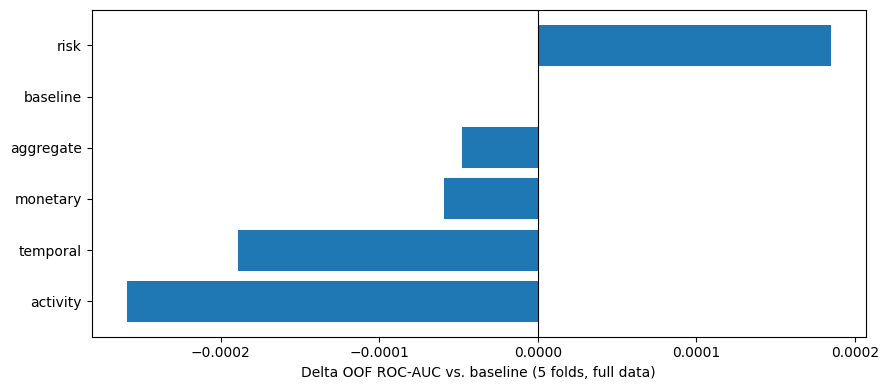

,feature,gain
0,cvv_retry_count,98626.595998
1,fe_risk_flag_count,94466.262170
2,merchant_risk_score,69410.685968
3,velocity_score,49449.051915
4,auth_method,33614.529255
5,customer_age,22396.629625
6,merchant_category,8007.190325
7,hours_since_last_txn,7939.826998
8,amount_usd,6444.900712
9,fe_merchant_risk_times_amount,6180.169362


In [47]:
if results:
    baseline = results[0]
    comparison = pd.DataFrame([
        {
            'experiment': result['name'],
            'features': result['n_features'],
            'oof_auc': result['oof_auc'],
            'delta_oof_auc': result['oof_auc'] - baseline['oof_auc'],
            'folds_improved': int((
                np.array(result['fold_auc']) > np.array(baseline['fold_auc'])
            ).sum()),
        }
        for result in results
    ])
    display(comparison)
    print(
        f"Best: {best['name']} | OOF AUC {best['oof_auc']:.6f} "
        f"| groups={best['groups']}"
    )

    plot = comparison.sort_values('delta_oof_auc')
    figure, axis = plt.subplots(figsize=(9, 4))
    axis.barh(plot.experiment, plot.delta_oof_auc)
    axis.axvline(0, color='black', linewidth=0.8)
    axis.set_xlabel('Delta OOF ROC-AUC vs. baseline (5 folds, full data)')
    figure.tight_layout()
    plt.show()
    plt.close(figure)

    importance_path = active_output_dir / best['name'] / 'importance.csv'
    if importance_path.exists():
        display(pd.read_csv(importance_path).head(15))

## 10. Validate saved predictions

The notebook recomputes the score from ID-keyed OOF predictions. It checks test prediction IDs
against the order in `sample_submission.csv`, along with row count and probability range.

In [48]:
if best is not None:
    oof_path = active_output_dir / best['name'] / 'oof.csv'
    prediction_path = active_output_dir / best['name'] / 'test_predictions.csv'
    if oof_path.exists() and prediction_path.exists():
        oof = pd.read_csv(oof_path)
        predictions = pd.read_csv(prediction_path)
        assert train.id.equals(oof.id), 'OOF IDs do not match training IDs'
        assert abs(roc_auc_score(train.is_fraud, oof.is_fraud) - best['oof_auc']) < 1e-12
        assert list(predictions) == ['id', 'is_fraud']
        assert sample.id.equals(predictions.id), 'Test ID order does not match the sample submission'
        assert predictions.is_fraud.between(0, 1).all()
        print('OK: OOF score and test prediction format verified.', len(predictions), 'test rows')
    else:
        print('Prediction files are incomplete. Run or resume CV before handing off the results.')

OK: OOF score and test prediction format verified. 299984 test rows


## 11. Export Parquet datasets

Set `EXPORT_DATASETS=True` in the settings cell to rebuild files.
The `features/` folder contains all row-level candidates (44 features); `features/recommended/`
contains the best configuration when it consists only of row-level features.

Fit aggregate statistics inside each training fold. Do not export one globally aggregated dataset
for CV. IDs and the target remain in the exported files for joining; exclude them from model inputs.

In [49]:
def build(data_dir, output_dir, groups=ROW_GROUPS):
    """Export row-level features with IDs and labels for the team handoff.

    Aggregates must be fitted inside CV folds and cannot use this export path.
    """
    groups = validate_groups(groups)
    if 'aggregate' in groups:
        raise ValueError(
            'Aggregate features must be fitted inside each CV fold; '
            'use the CV evaluation section of this notebook'
        )

    output_dir.mkdir(parents=True, exist_ok=True)
    manifest = {
        'groups': groups,
        'aggregate_features_included': False,
        'datasets': {},
    }

    for name in ('train', 'test'):
        raw = read_input_frame(data_dir, name)
        if raw.id.isna().any() or raw.id.duplicated().any():
            raise ValueError(f'{name}: IDs must be present and unique')

        features = add_row_features(raw, groups)
        for column in features.columns:
            if column.startswith('fe_'):
                features[column] = features[column].astype('float32')
        features.insert(0, 'id', raw.id)
        if name == 'train':
            features['is_fraud'] = raw.is_fraud

        output = output_dir / f'{name}_featured.parquet'
        features.to_parquet(output, index=False)
        manifest['datasets'][name] = {
            'rows': len(features),
            'columns': features.columns.tolist(),
            'file': output.name,
        }
        print(f'{output}: {features.shape}', flush=True)

    (output_dir / 'manifest.json').write_text(
        json.dumps(manifest, indent=2), encoding='utf-8'
    )

### 11.1. Export selected datasets

In [50]:
if EXPORT_DATASETS:
    build(DATA_DIR, FEATURE_DIR, ROW_GROUPS)
    if best is not None and 'aggregate' not in best['groups']:
        build(DATA_DIR, FEATURE_DIR / 'recommended', best['groups'])
    elif best is not None:
        print('The best configuration includes aggregates; use fit/transform inside each fold.')
    else:
        print('Candidate datasets were exported; run CV to select the recommended configuration.')

exports = []
for folder in (FEATURE_DIR, FEATURE_DIR / 'recommended'):
    for name in ('train_featured.parquet', 'test_featured.parquet'):
        path = folder / name
        if path.exists():
            info = pq.read_metadata(path)
            exports.append({'file': str(path.relative_to(ROOT)), 'rows': info.num_rows,
                            'columns': info.num_columns, 'size_mb': round(path.stat().st_size / 1024**2, 2)})
display(pd.DataFrame(exports))

f:\import doc\COLLAGE SEMESTER 7 TEL U\Visdat\tubes lomba UAS & UTS\tubesLomba_visdat\ps-s6e11\features\train_featured.parquet: (699960, 46)
f:\import doc\COLLAGE SEMESTER 7 TEL U\Visdat\tubes lomba UAS & UTS\tubesLomba_visdat\ps-s6e11\features\test_featured.parquet: (299984, 45)
f:\import doc\COLLAGE SEMESTER 7 TEL U\Visdat\tubes lomba UAS & UTS\tubesLomba_visdat\ps-s6e11\features\recommended\train_featured.parquet: (699960, 31)
f:\import doc\COLLAGE SEMESTER 7 TEL U\Visdat\tubes lomba UAS & UTS\tubesLomba_visdat\ps-s6e11\features\recommended\test_featured.parquet: (299984, 30)


,file,rows,columns,size_mb
0,ps-s6e11\features\train_featured.parquet,699960,46,33.41
1,ps-s6e11\features\test_featured.parquet,299984,45,15.24
2,ps-s6e11\features\recommended\train_featured.p...,699960,31,17.12
3,ps-s6e11\features\recommended\test_featured.pa...,299984,30,7.72


## 12. Handoff to Persons 1 and 4

To reuse the features in another notebook, copy the definitions from sections **3 and 4**
(constants, helpers, `add_row_features`, and `FraudFeatureEngineer`) and import NumPy/Pandas.
The callback below uses the best groups selected by this notebook.

In Person 1's notebook, use the team's baseline parameters and call
`run_cv('lgb_features', feature_fit_predict)` after defining the callback.
The `run_cv` function remains part of Person 1's pipeline.

Person 4 can use the recommended dataset in `ps-s6e11/features/recommended/`.
Use the team folds and fit categorical encoding on each training fold only.

In [51]:
chosen_groups = tuple(best['groups']) if best is not None else ('risk',)


def feature_fit_predict(X_tr, y_tr, X_va, y_va, X_te):
    """Adapt the feature engineer to Person 1's existing run_cv callback."""
    engineer = FraudFeatureEngineer(groups=chosen_groups)
    training_features = engineer.fit_transform(X_tr)
    validation_features = engineer.transform(X_va)
    test_features = engineer.transform(X_te)

    model = lgb.LGBMClassifier(**PARAMS)
    model.fit(
        training_features,
        y_tr,
        eval_set=[(validation_features, y_va)],
        eval_metric='auc',
        callbacks=[lgb.early_stopping(200, verbose=False)],
    )
    return (
        model.predict_proba(validation_features)[:, 1],
        model.predict_proba(test_features)[:, 1],
    )


print('Feature groups for the callback:', chosen_groups)

Feature groups for the callback: ('risk',)


## 13. Full report

This report comes from the active experiment folder. Predictions and datasets are artifacts;
all Person 3 implementation code lives in this notebook.

In [52]:
if active_report_dir is not None:
    report_path = active_report_dir / 'FEATURE_FINDINGS.md'
    if report_path.exists():
        display(Markdown(report_path.read_text(encoding='utf-8')))

# Feature engineering results

Full data: 699,960 training rows; five folds from data/folds.csv; model seed 42.
All experiments use the same LightGBM parameters and early stopping.
The baseline was rerun in this environment instead of copying a score from an older notebook.

| Experiment | Features | OOF AUC | Delta vs. baseline | Improved folds |
|---|---:|---:|---:|---:|
| baseline | 24 | 0.946318 | +0.000000 | 0/5 |
| monetary | 28 | 0.946259 | -0.000059 | 3/5 |
| activity | 30 | 0.946059 | -0.000259 | 0/5 |
| temporal | 29 | 0.946129 | -0.000189 | 1/5 |
| risk | 29 | 0.946503 | +0.000185 | 5/5 |
| aggregate | 45 | 0.946270 | -0.000048 | 3/5 |

The highest OOF AUC was **risk** (0.946503), using the five risk features.

Feature selection and scoring used the same CV folds, so this gain is exploratory,
not an independent estimate after selection. Confirm it with a separate holdout or evaluation.
Check per-fold deltas in `feature_experiments.csv`; a small difference alone does not
establish a consistent improvement.

## Integration

Create a new `FraudFeatureEngineer` in each fold. Fit it only on that fold's training rows,
then transform validation and test. Mean/std/min/max aggregates describe merchant/channel
groups rather than customer history. OOF and test prediction files are saved per experiment
with the original IDs. No Kaggle submission is made.

Best prediction folder: `ps-s6e11/features/experiments/risk`.

## Dataset details

24 original features: 5 categorical, 6 boolean, and 13 numeric. No full timestamp or customer ID is available.
Fraud rate: 1.6700%.

## Target distribution by fold

- Fold 0: 139,992 rows, fraud 1.6694%.
- Fold 1: 139,992 rows, fraud 1.6701%.
- Fold 2: 139,992 rows, fraud 1.6701%.
- Fold 3: 139,992 rows, fraud 1.6701%.
- Fold 4: 139,992 rows, fraud 1.6701%.
